# Confounding and covariate shift: results


**Notation:** $b$ denotes the location parameter and $a$ the scale multiplier. **OOD** labels denote the shifted condition; **IID** denotes the unshifted control.


In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT_DIR = Path(r"D:\Relational ML\confounding_covariate_shift_performance")
EXPERIMENT = "sampled_shifts"  # Change to "fixed_shifts" for the other diagnostics.
experiment_labels = {"fixed_shifts": "Fixed shifts", "sampled_shifts": "Sampled shifts"}
FIG_DIR = ROOT_DIR / EXPERIMENT / "figures"
modes, conditions = ["confounding", "covariate"], ["identity", "shift"]
condition_labels = {"identity": "IID", "shift": "OOD"}
keys = ["training_graph_u_mode", "training_condition", "test_graph_u_mode", "test_condition"]
metrics = ["accuracy", "balanced_accuracy", "macro_f1", "roc_auc", "nll", "brier"]
order = [f"{mode.title()} · {condition_labels[condition]}" for mode in modes for condition in conditions]
expected = pd.MultiIndex.from_product([modes, conditions, modes, conditions], names=keys)

def load_experiment(name):
    folder = ROOT_DIR / name
    frames = {"summary": [], "per_repetition": []}
    if name == "sampled_shifts":
        frames = {kind: [pd.read_csv(folder / f"{kind}.csv")] for kind in frames}
    else:
        for train_mode in modes:
            for test_mode in modes:
                for kind in frames:
                    frame = pd.read_csv(folder / f"{train_mode}_on_{test_mode}_{kind}.csv")
                    for column, value in zip([keys[0], keys[2]], [train_mode, test_mode]):
                        if column in frame:
                            assert frame[column].eq(value).all(), f"Wrong setting in {column}"
                        frame[column] = value
                    frames[kind].append(frame)
    summary, per_rep = [pd.concat(frames[kind], ignore_index=True) for kind in frames]
    assert len(summary) == 16 and not summary.duplicated(keys).any()
    assert set(summary.set_index(keys).index) == set(expected)
    assert summary["repetition_count"].eq(5).all()
    assert len(per_rep) == 80 and not per_rep.duplicated(keys + ["repetition"]).any()
    assert set(per_rep["repetition"]) == set(range(1, 6))
    assert set(per_rep.set_index(keys).index) == set(expected)
    assert per_rep.groupby(keys).size().eq(5).all()
    recomputed = per_rep.groupby(keys)[metrics].agg(["mean", "std"]).sort_index()
    recomputed.columns = [f"{metric}_{stat}" for metric, stat in recomputed.columns]
    np.testing.assert_allclose(summary.set_index(keys).sort_index()[recomputed.columns],
                               recomputed, rtol=0, atol=1e-12)
    for frame in (summary, per_rep):
        frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
        frame["test"] = frame[keys[2]].str.title() + " · " + frame[keys[3]].map(condition_labels)
    return summary, per_rep

experiments = {name: load_experiment(name) for name in experiment_labels}
results, repetitions = experiments[EXPERIMENT]
experiment_title = experiment_labels[EXPERIMENT]

def matrix(metric, stat="mean", experiment=EXPERIMENT):
    return experiments[experiment][0].pivot(index="model", columns="test",
        values=f"{metric}_{stat}").reindex(index=order, columns=order)

def show_plot(fig, name, folder=FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / f"{name}.png", dpi=250, bbox_inches="tight")
    plt.show()

plt.rcParams.update({"font.size": 10, "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False})
colors = ["#7543A3", "#07889B"]
print(f"Loaded both experiments: 16 comparisons × 5 repetitions each. Diagnostics: {experiment_title}.")

Loaded both experiments: 16 comparisons × 5 repetitions each. Diagnostics: Sampled shifts.


## Combined comparison table

Change `METRIC` to
`accuracy`, `balanced_accuracy`, `macro_f1`, `nll` or `brier` to inspect the other metrics.


Both experiments are shown. The remaining diagnostic figures use `EXPERIMENT`
from the loading cell (sampled shifts by default).

In [2]:
METRIC = "roc_auc"
metric_names = {"roc_auc": "AUROC", "accuracy": "Accuracy",
                "balanced_accuracy": "Balanced accuracy", "macro_f1": "Macro-F1",
                "nll": "NLL", "brier": "Brier score"}
for experiment, title in experiment_labels.items():
    means, sds = matrix(METRIC, experiment=experiment), matrix(METRIC, "std", experiment)
    table = pd.DataFrame(
        [[f"{means.iloc[i, j]:.4f} ± {sds.iloc[i, j]:.4f}" for j in range(4)] for i in range(4)],
        index=pd.Index(order, name="Training setting"), columns=pd.Index(order, name="Test data"))
    display(table.style.set_caption(f"{title} — {metric_names[METRIC]}: mean ± sample SD (5 repetitions)")
            .set_properties(**{"white-space": "nowrap"}))

Test data,Confounding · IID,Confounding · OOD,Covariate · IID,Covariate · OOD
Training setting,,,,
Confounding · IID,0.9383 ± 0.0016,0.8850 ± 0.0032,0.9354 ± 0.0019,0.9143 ± 0.0018
Confounding · OOD,0.9325 ± 0.0026,0.8783 ± 0.0035,0.9286 ± 0.0023,0.9062 ± 0.0038
Covariate · IID,0.9385 ± 0.0024,0.8855 ± 0.0036,0.9361 ± 0.0026,0.9151 ± 0.0034
Covariate · OOD,0.9356 ± 0.0023,0.8810 ± 0.0038,0.9326 ± 0.0027,0.9114 ± 0.0038


Test data,Confounding · IID,Confounding · OOD,Covariate · IID,Covariate · OOD
Training setting,,,,
Confounding · IID,0.9383 ± 0.0016,0.8846 ± 0.0019,0.9354 ± 0.0019,0.9132 ± 0.0030
Confounding · OOD,0.9318 ± 0.0020,0.8775 ± 0.0023,0.9281 ± 0.0027,0.9050 ± 0.0029
Covariate · IID,0.9385 ± 0.0024,0.8856 ± 0.0032,0.9361 ± 0.0026,0.9142 ± 0.0030
Covariate · OOD,0.9351 ± 0.0026,0.8812 ± 0.0032,0.9321 ± 0.0033,0.9104 ± 0.0033


## 1. Overall AUROC




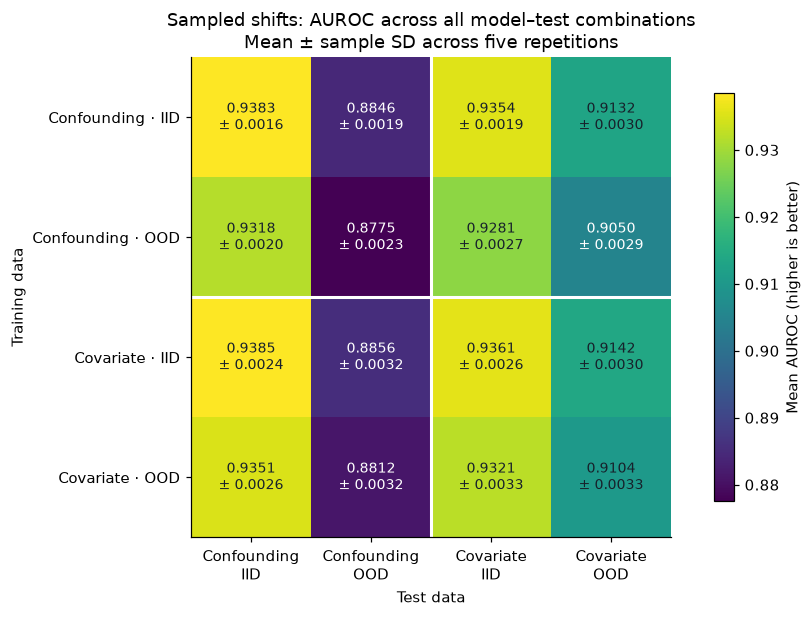

In [3]:
auc, auc_sd = matrix("roc_auc"), matrix("roc_auc", "std")
wrapped = [label.replace(" · ", "\n") for label in order]
fig, ax = plt.subplots(figsize=(9, 5.5), layout="constrained")
image = ax.imshow(auc.to_numpy(), cmap="viridis")
midpoint = (auc.to_numpy().min() + auc.to_numpy().max()) / 2
for i in range(4):
    for j in range(4):
        value = auc.iloc[i, j]
        ax.text(j, i, f"{value:.4f}\n± {auc_sd.iloc[i, j]:.4f}",
                ha="center", va="center", fontsize=9,
                color="white" if value < midpoint else "#17212B")
ax.set_xticks(range(4), wrapped)
ax.set_yticks(range(4), order)
ax.axhline(1.5, color="white", lw=2)
ax.axvline(1.5, color="white", lw=2)
ax.set(xlabel="Test data", ylabel="Training data",
       title=f"{experiment_title}: AUROC across all model–test combinations\nMean ± sample SD across five repetitions")
fig.colorbar(image, ax=ax, label="Mean AUROC (higher is better)", shrink=0.85)
show_plot(fig, "01_auroc_matrix")


## 2. Absolute AUROC by training setting

Each training setting has four points. Color identifies confounding/covariate test data;
filled circles indicate IID tests and open squares indicate OOD tests.
The points are slightly offset vertically for readability. Error bars are ± sample SD
across the five repetitions.


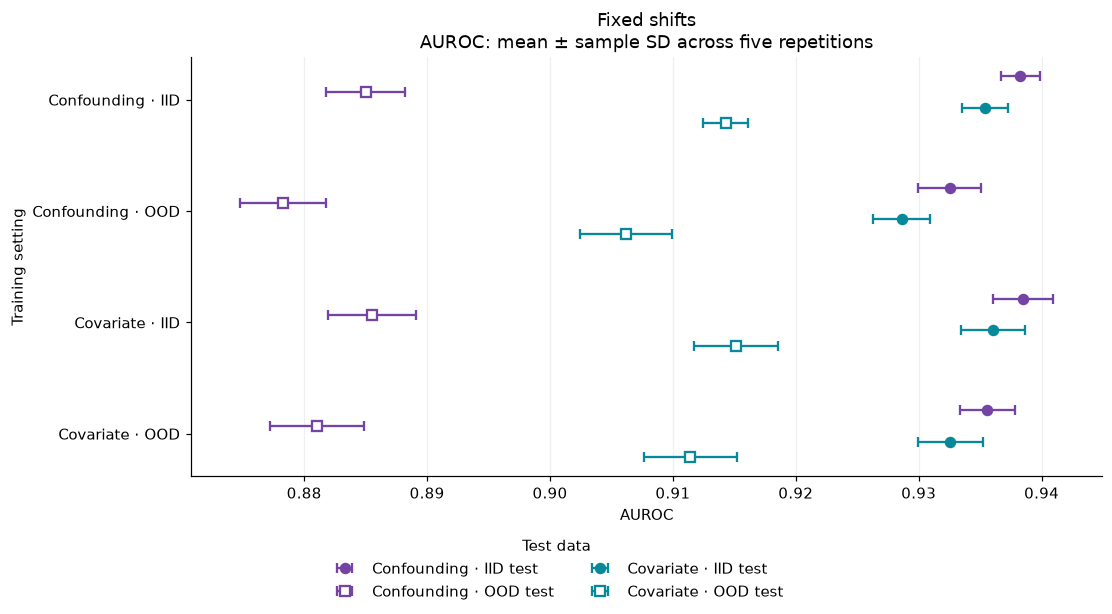

In [4]:
def draw_absolute_auroc(ax, means, sds):
    for j, offset in enumerate(np.linspace(-0.21, 0.21, 4)):
        iid, color = j % 2 == 0, colors[j // 2]
        label = f"{modes[j // 2].title()} · {'IID' if iid else 'OOD'} test"
        ax.errorbar(means.iloc[:, j], np.arange(4) + offset, xerr=sds.iloc[:, j],
                    fmt="o" if iid else "s", linestyle="none", markersize=6, capsize=3,
                    color=color, markerfacecolor=color if iid else "white",
                    markeredgewidth=1.5, label=label)
    ax.set_yticks(range(4), order)
    ax.grid(axis="x", alpha=0.2)
    ax.set(xlabel="AUROC", ylabel="Training setting")

def absolute_auroc_plot(means, sds, title, name, folder, xlim):
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    draw_absolute_auroc(ax, means, sds)
    ax.invert_yaxis()
    ax.set_xlim(xlim)
    ax.set_title(f"{title}\nAUROC: mean ± sample SD across five repetitions", fontsize=12)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center",
               ncol=2, frameon=False, title="Test data")
    show_plot(fig, name, folder)

bounds = [(matrix("roc_auc", experiment=name) + sign * matrix("roc_auc", "std", name)).to_numpy()
          for name in experiment_labels for sign in (-1, 1)]
comparison_xlim = (min(values.min() for values in bounds) - 0.004,
                   max(values.max() for values in bounds) + 0.004)
absolute_auroc_plot(matrix("roc_auc", experiment="fixed_shifts"),
                    matrix("roc_auc", "std", "fixed_shifts"), "Fixed shifts",
                    "01b_absolute_auroc", ROOT_DIR / "fixed_shifts" / "figures", comparison_xlim)


### Sampled shifts

The fixed- and sampled-shift figures use the same axis limits, colors, markers and
sample-SD error bars. In the sampled experiment, shift parameters vary per task
in both pretraining and OOD evaluation data; the IID controls use no
source-distribution shift.


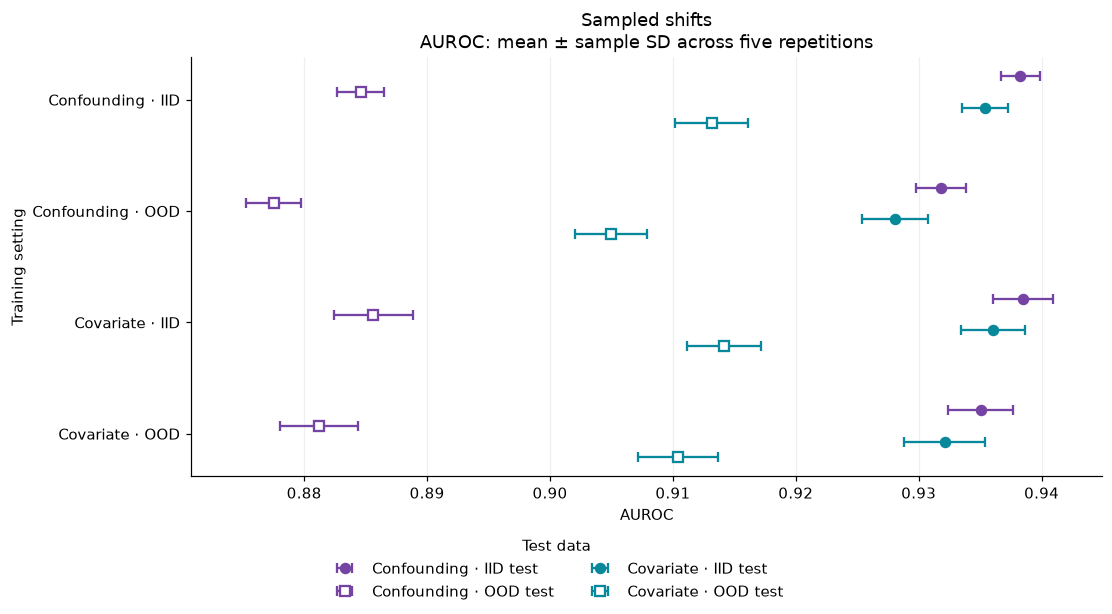

test,Confounding · IID,Confounding · OOD,Covariate · IID,Covariate · OOD
model,,,,
Confounding · IID,+0.0000,-0.0004,+0.0000,-0.0011
Confounding · OOD,-0.0007,-0.0008,-0.0006,-0.0012
Covariate · IID,+0.0000,+0.0001,+0.0000,-0.0009
Covariate · OOD,-0.0005,+0.0002,-0.0005,-0.0010


In [5]:
absolute_auroc_plot(matrix("roc_auc", experiment="sampled_shifts"),
                    matrix("roc_auc", "std", "sampled_shifts"), "Sampled shifts",
                    "01b_absolute_auroc", ROOT_DIR / "sampled_shifts" / "figures", comparison_xlim)

difference = matrix("roc_auc", experiment="sampled_shifts") - matrix("roc_auc", experiment="fixed_shifts")
display(difference.style.format("{:+.4f}").set_caption("Mean AUROC difference: sampled − fixed shifts"))


## 3. How much does each test shift hurt?

The y-axis identifies the training setting; the legend identifies the test data.
For each repetition, compute AUROC on IID tests minus AUROC on OOD tests.
Dots and error bars show the **mean ± sample SD of those five paired drops**.


,Confounding,Covariate
Training setting,,
Confounding · IID,0.0537 ± 0.0025,0.0222 ± 0.0031
Confounding · OOD,0.0543 ± 0.0031,0.0231 ± 0.0033
Covariate · IID,0.0529 ± 0.0035,0.0219 ± 0.0031
Covariate · OOD,0.0538 ± 0.0029,0.0217 ± 0.0031


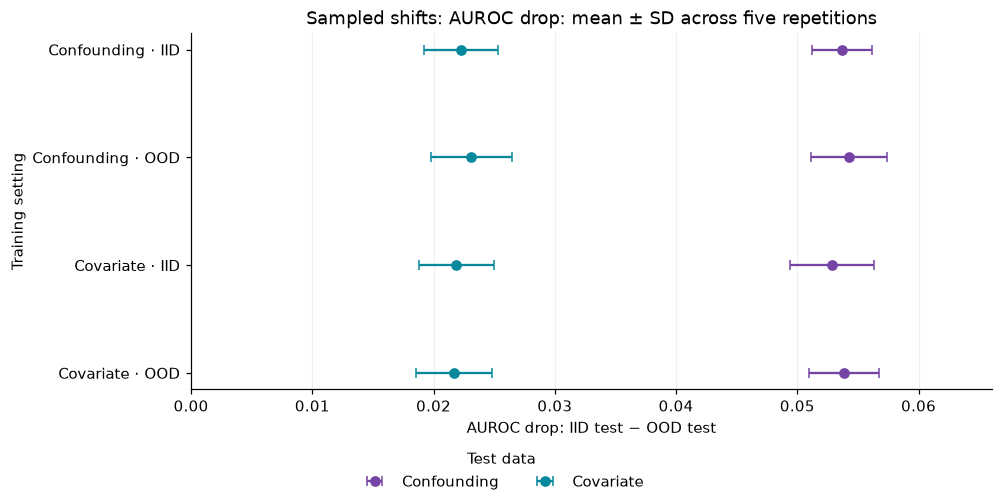

In [6]:
paired = repetitions.pivot(index=["model", "test_graph_u_mode", "repetition"],
                           columns="test_condition", values="roc_auc")
drops = (paired["identity"] - paired["shift"]).groupby(level=["model", "test_graph_u_mode"])
drop_stats = drops.agg(["mean", "std"])
penalty, penalty_sd = [drop_stats[stat].unstack().reindex(index=order, columns=modes).to_numpy()
                       for stat in ("mean", "std")]
drop_table = pd.DataFrame(
    [[f"{penalty[i, j]:.4f} ± {penalty_sd[i, j]:.4f}" for j in range(2)] for i in range(4)],
    index=pd.Index(order, name="Training setting"), columns=["Confounding", "Covariate"])
display(drop_table.style.set_caption(f"{experiment_title}: AUROC drop: mean ± sample SD across five repetitions"))

def plot_penalty(labels, name):
    idx = [order.index(label) for label in labels]
    fig, ax = plt.subplots(figsize=(9, 1.3 + 0.8 * len(idx)), layout="constrained")
    for j, mode in enumerate(modes):
        ax.errorbar(penalty[idx, j], np.arange(len(idx)), xerr=penalty_sd[idx, j],
                    fmt="o", linestyle="none", markersize=6, capsize=3,
                    color=colors[j], label=mode.title())
    ax.set_yticks(range(len(idx)), labels)
    ax.invert_yaxis()
    ax.set_xlim(0, (penalty[idx] + penalty_sd[idx]).max() * 1.15)
    ax.grid(axis="x", alpha=0.2)
    ax.set(xlabel="AUROC drop: IID test − OOD test", ylabel="Training setting",
           title=f"{experiment_title}: AUROC drop: mean ± SD across five repetitions")
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center",
               ncol=2, frameon=False, title="Test data")
    show_plot(fig, name)

plot_penalty(order, "02_test_shift_penalty")


## 4. OOD-trained models only

The same paired AUROC drops, restricted to the two model groups trained on OOD data.


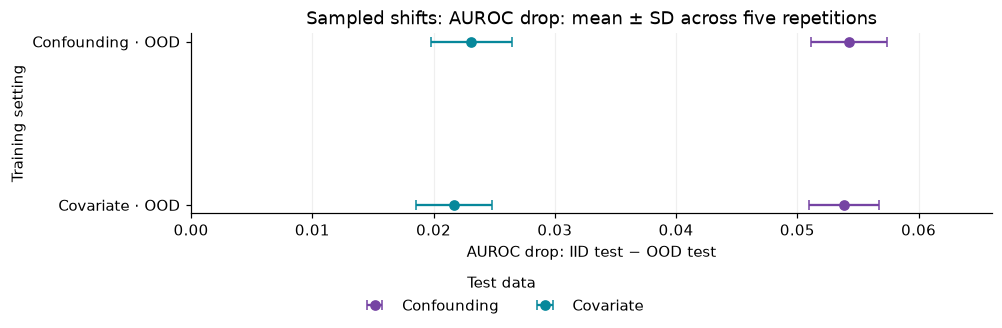

In [7]:
plot_penalty([order[1], order[3]], "02b_shift_trained_penalty")


## 5. Does OOD pretraining help?

Compare OOD- and IID-pretrained models within each training setting, on the same test banks.
Positive values favor OOD pretraining. Error bars are the **sample SD of five paired
repetition-level differences**.


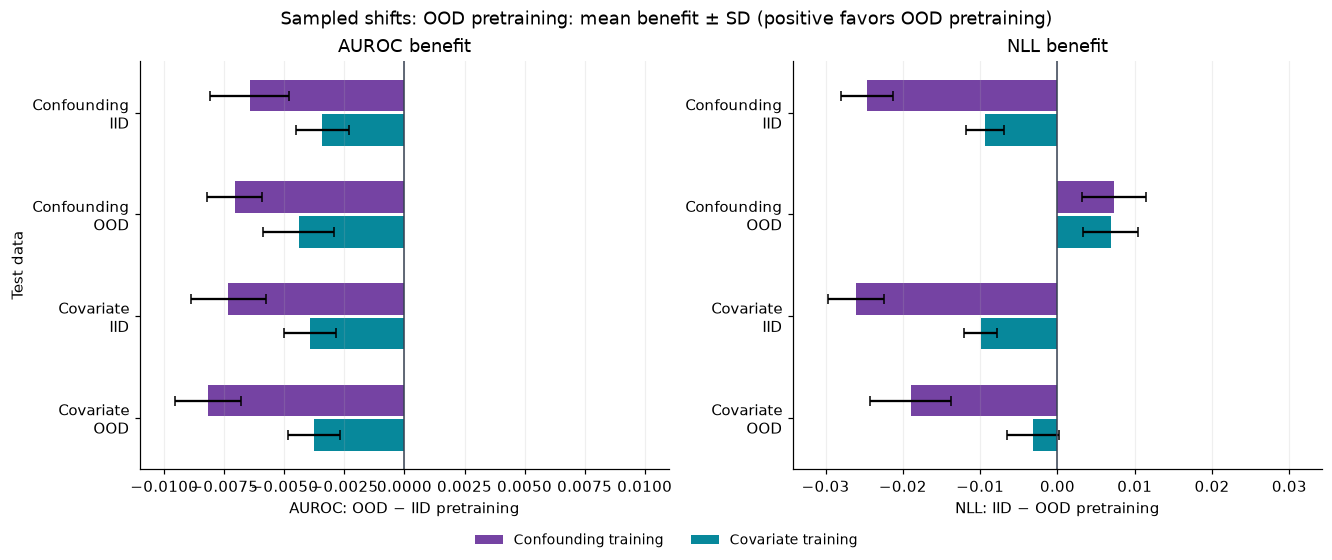

In [8]:
def pretraining_gain(metric, sign=1):
    paired = repetitions.pivot(index=["training_graph_u_mode", "test", "repetition"],
                               columns="training_condition", values=metric)
    stats = (sign * (paired["shift"] - paired["identity"])).groupby(
        level=["training_graph_u_mode", "test"]).agg(["mean", "std"])
    return [stats[stat].unstack().reindex(index=modes, columns=order).to_numpy()
            for stat in ("mean", "std")]

auc_gain, auc_gain_sd = pretraining_gain("roc_auc")
nll_gain, nll_gain_sd = pretraining_gain("nll", sign=-1)
y = np.arange(4)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
panels = [(auc_gain, auc_gain_sd, "AUROC benefit", "AUROC: OOD − IID pretraining"),
          (nll_gain, nll_gain_sd, "NLL benefit", "NLL: IID − OOD pretraining")]
for ax, (gain, sd, title, xlabel) in zip(axes, panels):
    for i, mode in enumerate(modes):
        ax.barh(y + (i - 0.5) * 0.34, gain[i], xerr=sd[i], height=0.31, capsize=3,
                color=colors[i], label=f"{mode.title()} training")
    bound = (np.abs(gain) + sd).max() * 1.15
    ax.set_xlim(-bound, bound)
    ax.axvline(0, color="#364152", lw=1)
    ax.set_yticks(y, wrapped)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.2)
    ax.set(title=title, xlabel=xlabel)
axes[0].set_ylabel("Test data")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center",
           ncol=2, frameon=False, fontsize=9)
fig.suptitle(f"{experiment_title}: OOD pretraining: mean benefit ± SD (positive favors OOD pretraining)", fontsize=12)
show_plot(fig, "03_shifted_pretraining_effect")


## Numerical readout

The numbers below are computed from the CSVs. They describe this model, these constructions,
the validation-selection procedure and the fixed training budget.


In [9]:
display(Markdown(f"""
- **Confounding-test AUROC drops:** {penalty[:, 0].min():.4f}–{penalty[:, 0].max():.4f}.
- **Covariate-test AUROC drops:** {penalty[:, 1].min():.4f}–{penalty[:, 1].max():.4f}.
- **OOD-pretraining AUROC changes:** {auc_gain.min():+.4f} to {auc_gain.max():+.4f}
  across the eight comparisons. Negative values favor IID pretraining.
- **Confounding OOD-test NLL benefit from OOD pretraining:**
  {nll_gain[0, 1]:+.4f} for confounding-trained models and
  {nll_gain[1, 1]:+.4f} for covariate-trained models. Positive values mean lower NLL.
"""))



- **Confounding-test AUROC drops:** 0.0529–0.0543.
- **Covariate-test AUROC drops:** 0.0217–0.0231.
- **OOD-pretraining AUROC changes:** -0.0082 to -0.0034
  across the eight comparisons. Negative values favor IID pretraining.
- **Confounding OOD-test NLL benefit from OOD pretraining:**
  +0.0073 for confounding-trained models and
  +0.0069 for covariate-trained models. Positive values mean lower NLL.


## 6. Evaluation across b values

These results reuse the selected models from the **sampled-shift experiment**:
the models, learning rates and weights stay fixed. Only the OOD test banks change.

Each task's query **b** is sampled from a truncated normal with underlying
normal SD **0.15**. The tested b means are **0.3, 1.3, 1.7, 1.9, 2.2,
4.5, 10 and 100**. Bounds are **mean ± 0.2**, except for mean **100**, which
uses **[85, 115]**. With SD 0.15, the latter draws remain close to 100.

For OOD tests, the **a distribution stays unchanged**: mean **1.5**,
underlying normal SD **0.1**, bounds **[1.3, 1.7]**. The OOD models were
pretrained with b mean **2.0**.

The IID results are reused references, not another numeric b.
Each b has a separate AUROC plot below, with identical colors, markers
and x-axis limits. All error bars are **± sample SD across five repetitions**.


In [10]:
LOCATION_DIR = ROOT_DIR / "location_sweep"
location_summary, location_repetitions = [
    pd.read_csv(LOCATION_DIR / f"{kind}.csv") for kind in ("summary", "per_repetition")]
location_means = [0.3, 1.3, 1.7, 1.9, 2.2, 4.5, 10, 100]
location_cases = ["IID"] + [f"μ={mean:g}" for mean in location_means]
location_keys = keys + ["location_mean"]
for frame in (location_summary, location_repetitions):
    assert frame["test_condition"].eq("identity").equals(frame["location_mean"].isna())
    assert set(frame["location_mean"].dropna()) == set(location_means)
    shifted = frame.loc[frame["test_condition"].eq("shift")]
    np.testing.assert_allclose(
        shifted[["scale_mean", "scale_std", "scale_min", "scale_max", "location_std"]]
        .drop_duplicates().to_numpy(), [[1.5, 0.1, 1.3, 1.7, 0.15]], rtol=0, atol=1e-12)
    frame["location_case"] = frame["location_mean"].map(lambda x: "IID" if pd.isna(x) else f"μ={x:g}")
    frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
    frame["test"] = frame[keys[2]].str.title() + " · " + frame[keys[3]].map(condition_labels)
assert len(location_summary) == 8 * (len(location_means) + 1)
assert not location_summary.duplicated(location_keys).any()
assert len(location_repetitions) == 5 * len(location_summary)
assert not location_repetitions.duplicated(location_keys + ["repetition"]).any()
assert location_summary["repetition_count"].eq(5).all()
groups = location_repetitions.groupby(location_keys, dropna=False)
assert groups["repetition"].agg(lambda x: set(x) == set(range(1, 6))).all()
recomputed = groups[metrics].agg(["mean", "std"]).sort_index()
recomputed.columns = [f"{metric}_{stat}" for metric, stat in recomputed.columns]
np.testing.assert_allclose(location_summary.set_index(location_keys).sort_index()[recomputed.columns],
                           recomputed, rtol=0, atol=1e-12)
location_expected = pd.MultiIndex.from_product([modes, conditions, modes, location_cases])
assert set(location_summary.set_index(keys[:3] + ["location_case"]).index) == set(location_expected)

# Confirm that these reports use the same selected models and IID reference scores.
model_keys = [keys[0], keys[1], "repetition"]
source = experiments["sampled_shifts"][1]
frozen = source.drop_duplicates(model_keys)[model_keys + ["checkpoint_sha256"]]
matched = location_repetitions.merge(frozen, on=model_keys, suffixes=("", "_source"), validate="many_to_one")
assert matched["checkpoint_sha256"].eq(matched["checkpoint_sha256_source"]).all()
iid = location_repetitions.loc[location_repetitions["test_condition"].eq("identity")].set_index(
    keys + ["repetition"])
np.testing.assert_allclose(iid[metrics], source.set_index(keys + ["repetition"]).reindex(iid.index)[metrics],
                           rtol=0, atol=1e-12)
print(f"Loaded {len(location_summary)} comparisons × 5 repetitions across {len(location_means)} b values; "
      "saved model hashes and reused IID scores match the sampled experiment.")


Loaded 72 comparisons × 5 repetitions across 8 b values; saved model hashes and reused IID scores match the sampled experiment.


In [11]:
location_xlim = ((location_summary["roc_auc_mean"] - location_summary["roc_auc_std"]).min() - 0.004,
                 (location_summary["roc_auc_mean"] + location_summary["roc_auc_std"]).max() + 0.004)
iid_reference = location_summary.loc[location_summary["test_condition"].eq("identity")]

def plot_test_location(mean):
    shifted = location_summary.loc[location_summary["location_mean"].eq(mean)]
    parameters = shifted[["location_std", "location_min", "location_max"]].drop_duplicates()
    assert len(parameters) == 1, f"Inconsistent location settings for mean {mean}"
    parameters = parameters.iloc[0]
    subset = pd.concat([iid_reference, shifted])
    means, sds = [subset.pivot(index="model", columns="test", values=f"roc_auc_{stat}")
                  .reindex(index=order, columns=order) for stat in ("mean", "std")]
    title = (f"Test b distribution: mean {mean:g}, "
             f"bounds [{parameters['location_min']:g}, {parameters['location_max']:g}]")
    tag = f"{mean:g}".replace(".", "p")
    absolute_auroc_plot(means, sds, title, f"auroc_location_{tag}",
                        LOCATION_DIR / "figures", location_xlim)


### Mean b = 0.3: bounds [0.1, 0.5]

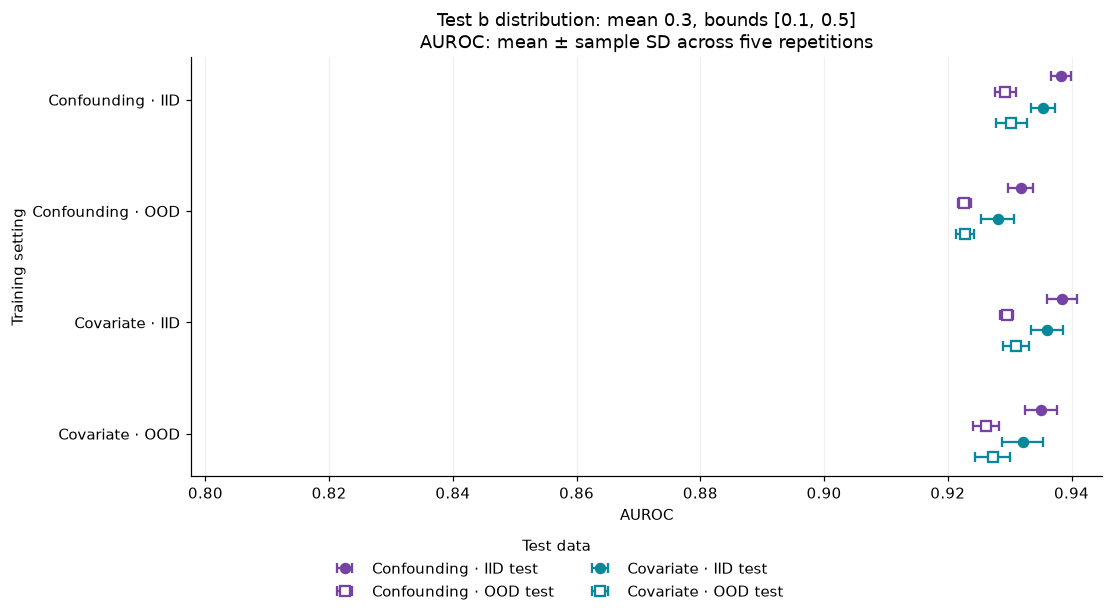

In [12]:
plot_test_location(0.3)

### Mean b = 1.3: bounds [1.1, 1.5]

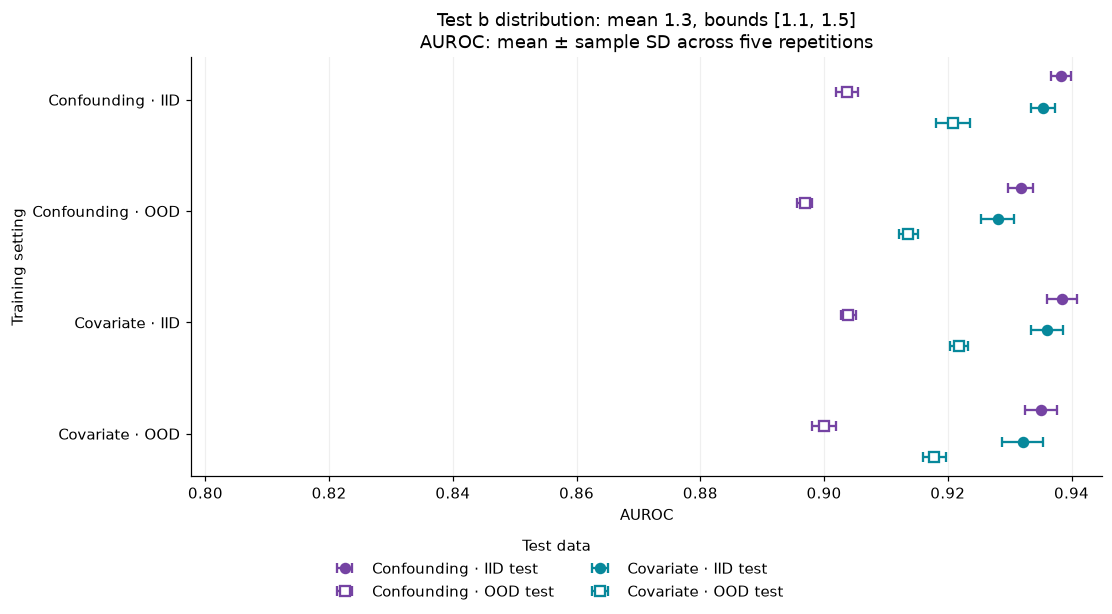

In [13]:
plot_test_location(1.3)

### Mean b = 1.7: bounds [1.5, 1.9]

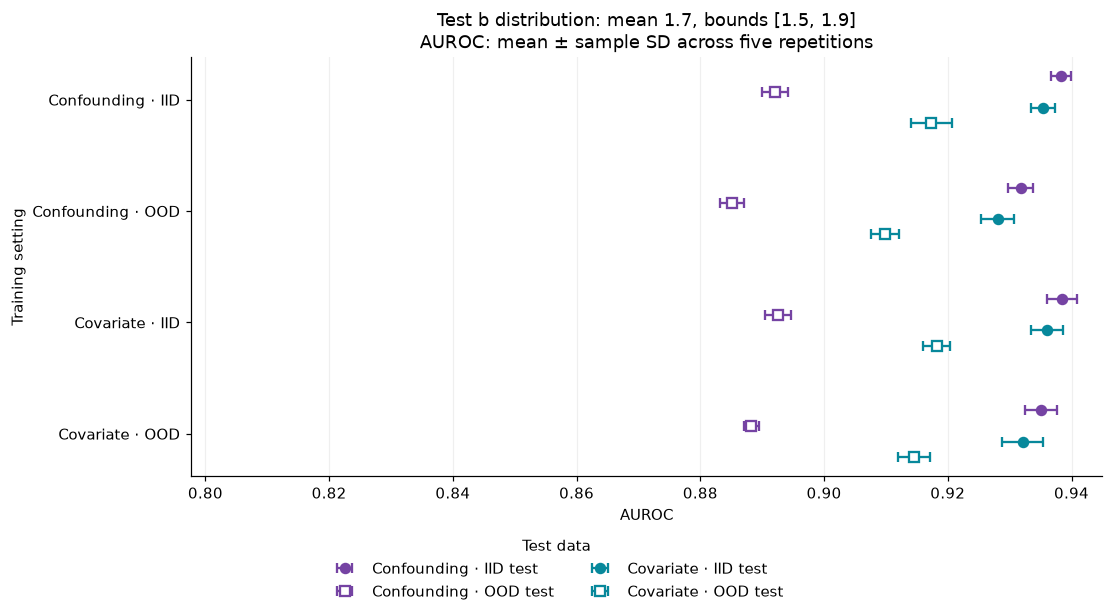

In [14]:
plot_test_location(1.7)

### Mean b = 1.9: bounds [1.7, 2.1]

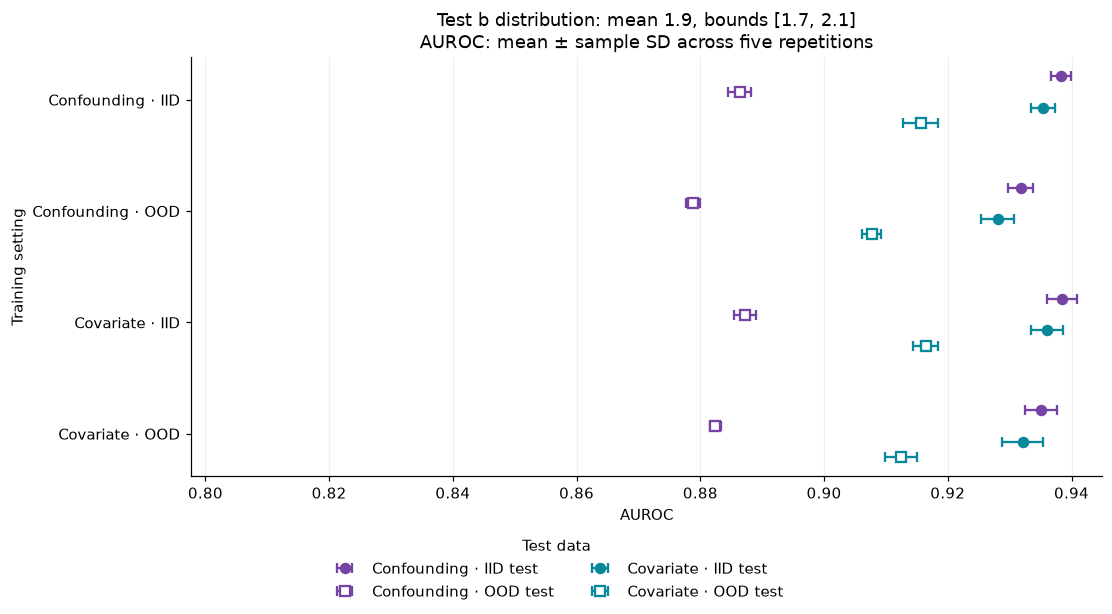

In [15]:
plot_test_location(1.9)

### Mean b = 2.2: bounds [2, 2.4]

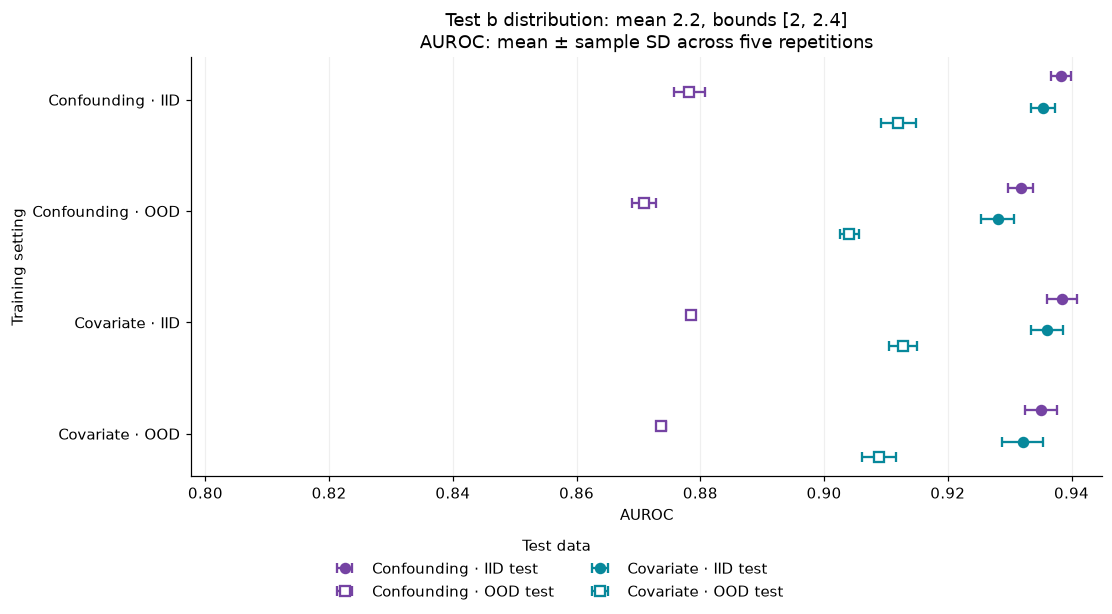

In [16]:
plot_test_location(2.2)

### Mean b = 4.5: bounds [4.3, 4.7]

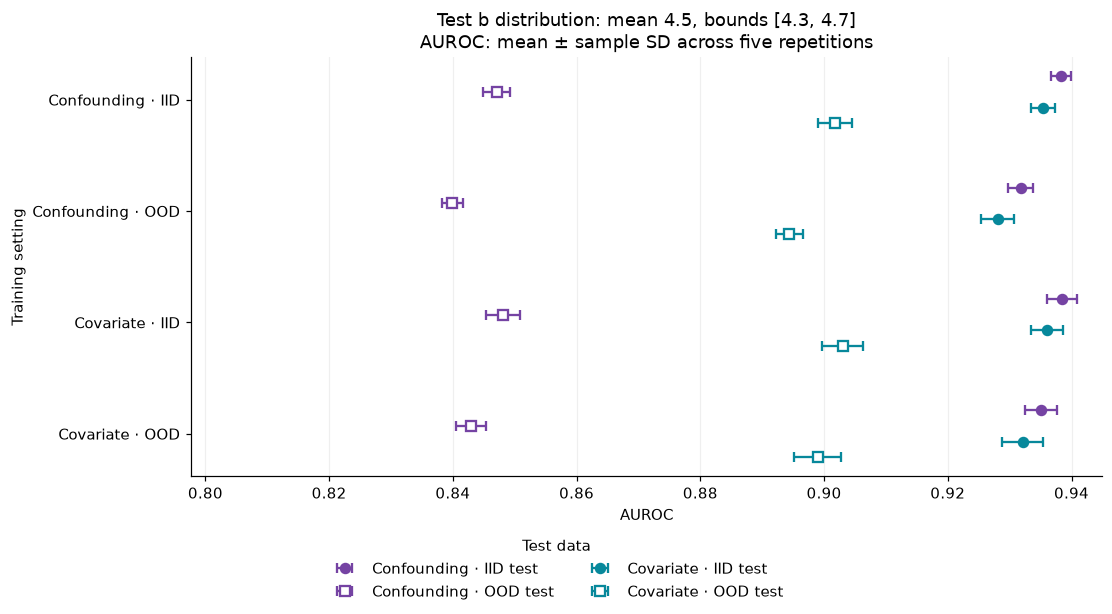

In [17]:
plot_test_location(4.5)

### Mean b = 10: bounds [9.8, 10.2]

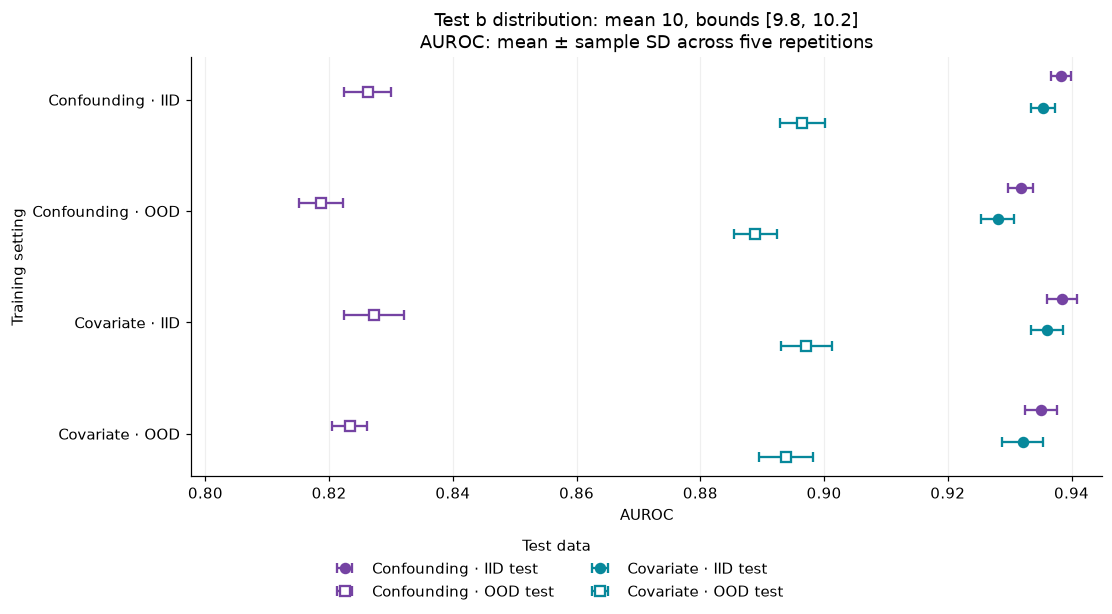

In [18]:
plot_test_location(10)

### Mean b = 100: bounds [85, 115]

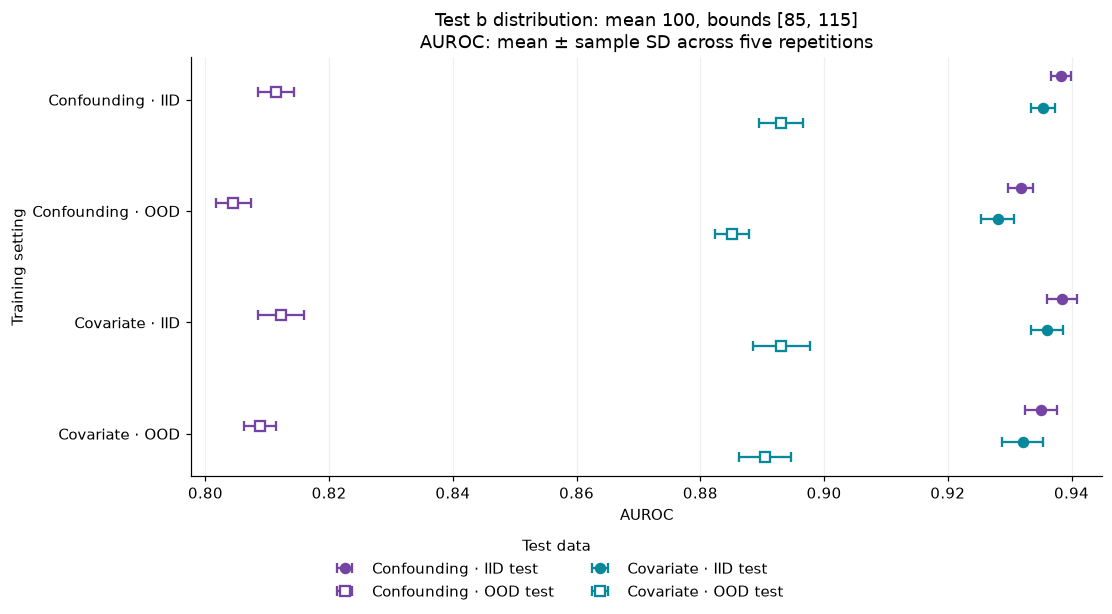

In [19]:
plot_test_location(100)

## 7. Fixed shift sweep in training and testing

For each fixed **(b, a)** pair below, the OOD models are retrained
and selected by matching-validation AUROC. Every OOD training, validation
and test task uses that exact pair; the magnitude is fixed across tasks.

The IID-trained models and IID test banks come from the **original fixed
experiment** (b = 2, a = 1.5 for its OOD tasks). Each repetition reuses
its corresponding IID model within the same graph setting. The existing
IID-on-IID scores are included as references.

Yellow triangles show each selected model's AUROC on its **own training bank**, scored on query rows using the stored support/query split with
weights fixed. Each row has one training point alongside its four test points.
Training error bars also show sample SD across the five repetitions.


In [20]:
FIXED_SWEEP_DIR = ROOT_DIR / "fixed_shift_train_test_sweep"
fixed_summary, fixed_repetitions = [
    pd.read_csv(FIXED_SWEEP_DIR / f"{kind}.csv") for kind in ("summary", "per_repetition")]
fixed_pairs = [(4, 1.5), (20, 2), (60, 3), (100, 4)]
pair_keys = ["fixed_location", "fixed_scale"]
fixed_keys = pair_keys + keys
for frame in (fixed_summary, fixed_repetitions):
    assert set(frame[pair_keys].itertuples(index=False, name=None)) == set(fixed_pairs)
    frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
    frame["test"] = frame[keys[2]].str.title() + " · " + frame[keys[3]].map(condition_labels)
assert len(fixed_summary) == 64 and not fixed_summary.duplicated(fixed_keys).any()
assert len(fixed_repetitions) == 320 and not fixed_repetitions.duplicated(fixed_keys + ["repetition"]).any()
assert fixed_summary["repetition_count"].eq(5).all()
assert fixed_repetitions["task_count"].eq(3200).all()
assert set(fixed_summary.set_index(fixed_keys).index) == {
    (*pair, *case) for pair in fixed_pairs for case in expected}
groups = fixed_repetitions.groupby(fixed_keys)
assert groups["repetition"].agg(lambda x: set(x) == set(range(1, 6))).all()
recomputed = groups[metrics].agg(["mean", "std"]).sort_index()
recomputed.columns = [f"{metric}_{stat}" for metric, stat in recomputed.columns]
np.testing.assert_allclose(fixed_summary.set_index(fixed_keys).sort_index()[recomputed.columns],
                           recomputed, rtol=0, atol=1e-12)

# Confirm fixed parameters on shifted tasks and location 0 / scale 1 on IID tasks.
for prefix, condition in (("training", "training_condition"), ("test", "test_condition")):
    for parameter, iid_value in (("location", 0), ("scale", 1)):
        values = np.where(fixed_repetitions[condition].eq("identity"), iid_value,
                          fixed_repetitions[f"fixed_{parameter}"])
        np.testing.assert_allclose(fixed_repetitions[f"{prefix}_query_{parameter}"],
                                   values, rtol=0, atol=1e-12)
assert fixed_repetitions["model_seed"].eq(41 + fixed_repetitions["repetition"]).all()
reused = fixed_repetitions[keys[1]].eq("identity") & fixed_repetitions[keys[3]].eq("identity")
assert fixed_repetitions["result_origin"].eq("reused_iid").equals(reused)

# Compare reused controls against the original FIXED experiment, by track and repetition.
fixed_source = experiments["fixed_shifts"][1]
for condition, match_keys, digest in (
    ("training_condition", ["training_graph_u_mode", "repetition"], "checkpoint_sha256"),
    ("test_condition", ["test_graph_u_mode", "repetition"], "test_dump_sha256"),
):
    baseline = fixed_source.loc[fixed_source[condition].eq("identity")]
    references = baseline.drop_duplicates(match_keys)[match_keys + [digest]]
    matched = fixed_repetitions.loc[fixed_repetitions[condition].eq("identity")].merge(
        references, on=match_keys, suffixes=("", "_original"), validate="many_to_one")
    assert matched[digest].eq(matched[f"{digest}_original"]).all()
iid = fixed_repetitions.loc[reused].set_index(keys + ["repetition"])
np.testing.assert_allclose(
    iid[metrics], fixed_source.set_index(keys + ["repetition"]).reindex(iid.index)[metrics],
    rtol=0, atol=1e-12)
print("Loaded four fixed train/test experiments: 64 comparisons × 5 repetitions; "
      "fixed parameters and original IID controls verified.")

# Own-training-bank scores for the same selected checkpoints as the test results.
training_summary, training_repetitions = [
    pd.read_csv(FIXED_SWEEP_DIR / f"training_{kind}.csv")
    for kind in ("summary", "per_repetition")]
training_keys = pair_keys + keys[:2]
assert len(training_summary) == 16 and not training_summary.duplicated(training_keys).any()
assert len(training_repetitions) == 80
assert not training_repetitions.duplicated(training_keys + ["repetition"]).any()
assert set(training_summary.set_index(training_keys).index) == {
    (*pair, mode, condition) for pair in fixed_pairs for mode in modes for condition in conditions}
assert training_summary["repetition_count"].eq(5).all()
assert training_repetitions["task_count"].eq(80000).all()
for frame in (training_summary, training_repetitions):
    assert frame["evaluation_split"].eq("training").all() and frame["scored_rows"].eq("query").all()
    frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
groups = training_repetitions.groupby(training_keys)
assert groups["repetition"].agg(lambda x: set(x) == set(range(1, 6))).all()
recomputed = groups[metrics].agg(["mean", "std"]).sort_index()
recomputed.columns = [f"{metric}_{stat}" for metric, stat in recomputed.columns]
np.testing.assert_allclose(training_summary.set_index(training_keys).sort_index()[recomputed.columns],
                           recomputed, rtol=0, atol=1e-12)
matched = training_repetitions.merge(fixed_repetitions, on=training_keys + ["repetition"],
                                     suffixes=("_train", "_test"), validate="one_to_many")
assert len(matched) == 320
assert matched["checkpoint_sha256_train"].eq(matched["checkpoint_sha256_test"]).all()


Loaded four fixed train/test experiments: 64 comparisons × 5 repetitions; fixed parameters and original IID controls verified.


In [21]:
fixed_sweep_xlim = (
    min((frame["roc_auc_mean"] - frame["roc_auc_std"]).min()
        for frame in (fixed_summary, training_summary)) - 0.004,
    max((frame["roc_auc_mean"] + frame["roc_auc_std"]).max()
        for frame in (fixed_summary, training_summary)) + 0.004)

def plot_fixed_train_test(location, scale):
    subset = fixed_summary.loc[
        fixed_summary["fixed_location"].eq(location) & fixed_summary["fixed_scale"].eq(scale)]
    means, sds = [subset.pivot(index="model", columns="test", values=f"roc_auc_{stat}")
                  .reindex(index=order, columns=order) for stat in ("mean", "std")]
    train = training_summary.loc[
        training_summary["fixed_location"].eq(location) &
        training_summary["fixed_scale"].eq(scale)].set_index("model").reindex(order)
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    draw_absolute_auroc(ax, means, sds)
    ax.errorbar(train["roc_auc_mean"], np.arange(4) + 0.34, xerr=train["roc_auc_std"],
                fmt="^", linestyle="none", markersize=7, capsize=3, markeredgewidth=1.2,
                color="#D4AA00", markerfacecolor="#FFD43B", markeredgecolor="#9E7B00",
                label="Own training data")
    ax.invert_yaxis()
    ax.set_xlim(fixed_sweep_xlim)
    ax.set_title(f"Fixed train/test parameters: b = {location:g}, a = {scale:g}\n"
                 "AUROC: mean ± sample SD across five repetitions", fontsize=12)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center",
               ncol=2, frameon=False, title="Data used for evaluation")
    tag = f"loc_{location:g}_scale_{scale:g}".replace(".", "p")
    show_plot(fig, f"auroc_{tag}", FIXED_SWEEP_DIR / "figures")


### Fixed b = 4, a = 1.5

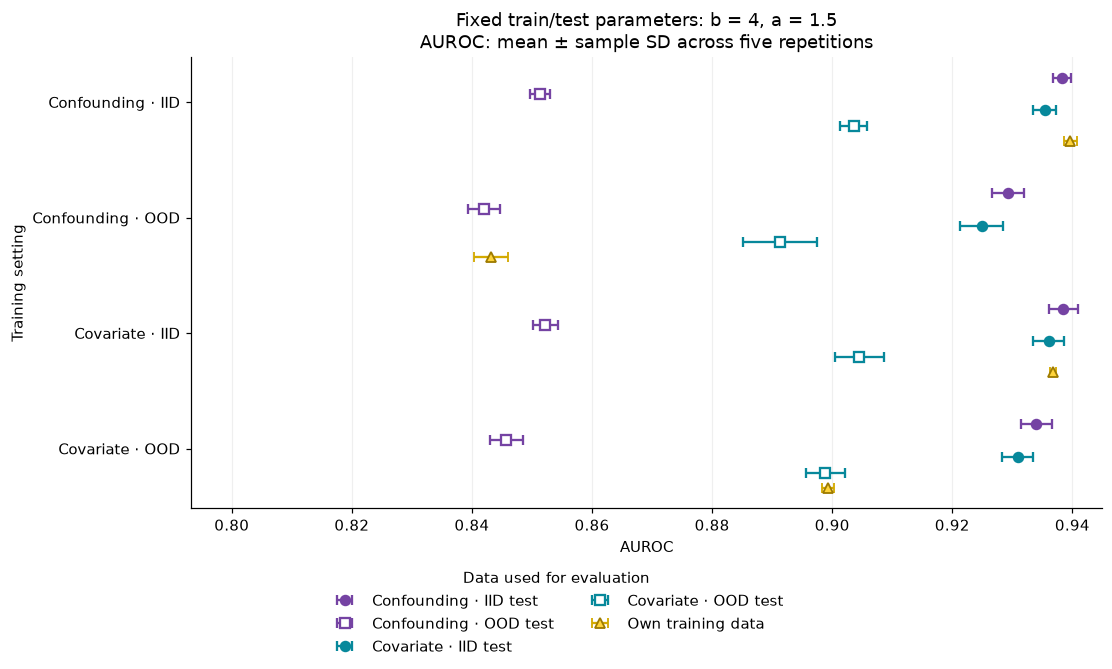

In [22]:
plot_fixed_train_test(4, 1.5)

### Fixed b = 20, a = 2

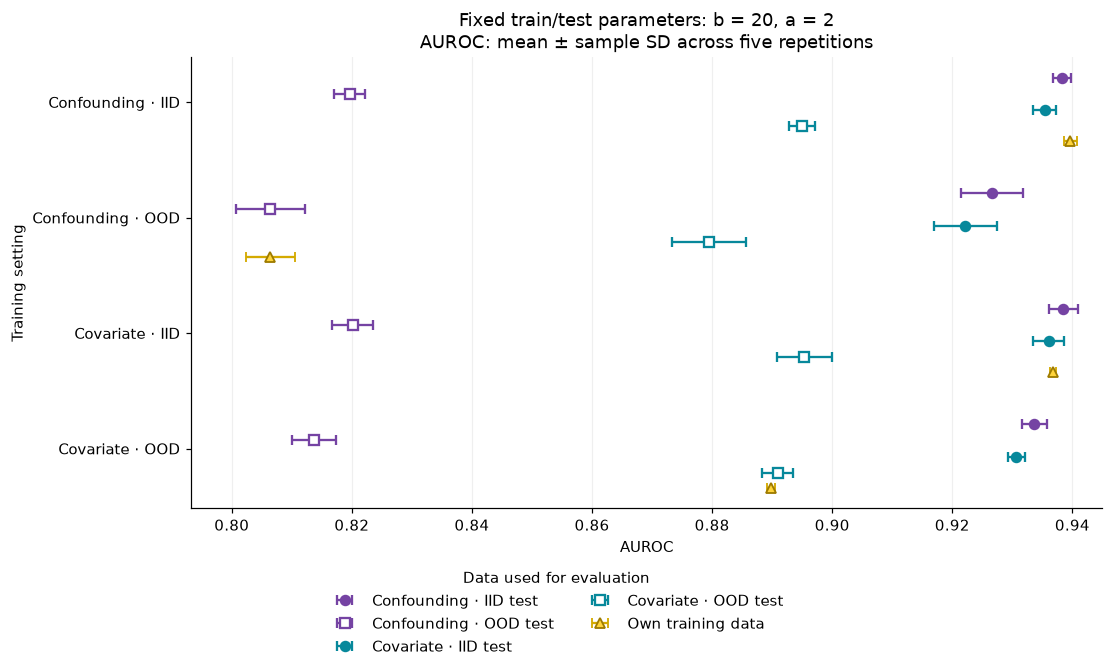

In [23]:
plot_fixed_train_test(20, 2)

### Fixed b = 60, a = 3

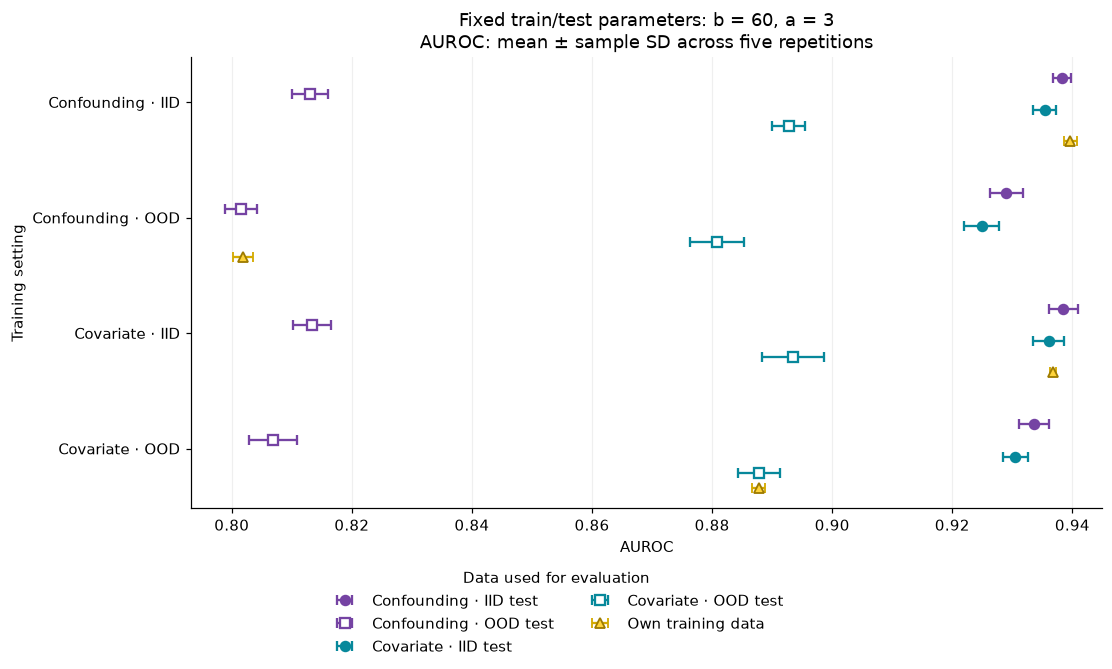

In [24]:
plot_fixed_train_test(60, 3)

### Fixed b = 100, a = 4

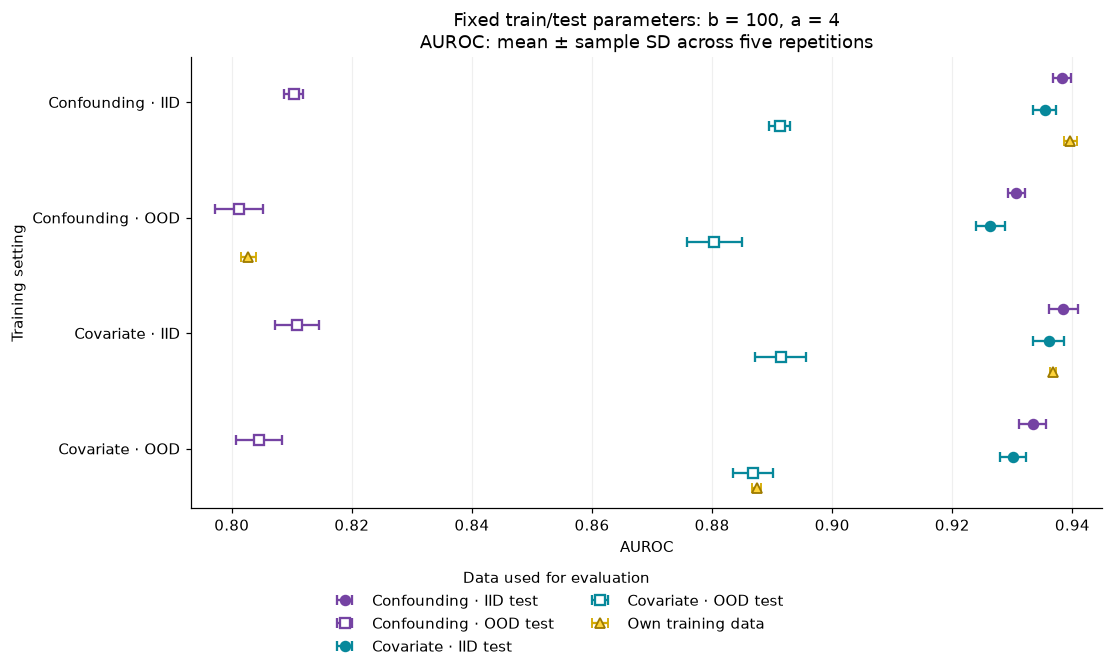

In [25]:
plot_fixed_train_test(100, 4)

## 8. Shuffled multi-epoch training: repetition 1

These runs reuse repetition 1's existing training and test banks and the shared
validation banks for each fixed shift pair. Whole training batches are reshuffled
reproducibly every epoch. Each candidate trains for its full **3-, 6- or 10-epoch**
budget; the learning rate is selected independently for each model and budget from
**0.0007, 0.001 and 0.002**, using matching-validation AUROC.

IID models are also retrained and tuned at each budget, then reused across the
four shift pairs. Each figure shows the four training settings on the same four
test settings as before. AUROC averages the 3,200 tasks in each test bank.

There is **one repetition**, so these plots have **no error bars across
repetitions**. Purple/teal identify confounding/covariate test data; filled circles
indicate IID tests and open squares indicate OOD tests. All twenty-four figures
share x-axis limits and have no connecting lines.

When the epoch experiment's training-evaluation CSVs are available, a **yellow
triangle** marks each selected model's AUROC on its **own 80,000 training tasks**,
scoring query rows with fixed weights. Each row then has one training point
alongside its four test points. These training markers also have no error bars.

For every shift pair and epoch budget, the **train = test shift** figure is
followed immediately by the corresponding **50% larger test shift** figure.
The latter uses test b and a equal to 1.5 times the OOD training
parameters: **6 / 2.25**, **30 / 3**, **90 / 4.5** and **150 / 6**.
The selected model weights, learning rates, IID test banks and training scores
are identical between each pair of plots. Only OOD test banks change.
Both versions use the same axis limits, colors and markers.


In [26]:
EPOCH_DIR = ROOT_DIR / "fixed_shift_train_test_epochs_shuffled"
epoch_summary, epoch_runs, epoch_winners = [
    pd.read_csv(EPOCH_DIR / f"{name}.csv")
    for name in ("summary", "per_repetition", "winners")]
epoch_budgets = [3, 6, 10]
epoch_keys = ["epochs"] + pair_keys + keys
epoch_expected = { (epoch, *pair, *case)
                   for epoch in epoch_budgets for pair in fixed_pairs for case in expected }
assert len(epoch_summary) == len(epoch_runs) == 192 and len(epoch_winners) == 30
for frame in (epoch_summary, epoch_runs):
    assert not frame.duplicated(epoch_keys).any()
    assert set(frame.set_index(epoch_keys).index) == epoch_expected
    frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
    frame["test"] = frame[keys[2]].str.title() + " · " + frame[keys[3]].map(condition_labels)
for frame in (epoch_summary, epoch_runs, epoch_winners):
    assert frame["shuffle_batches"].eq(True).all()
    assert frame["batch_order_scheme"].eq("seedsequence_model_epoch_v1").all()
assert epoch_summary["repetition_count"].eq(1).all() and epoch_runs["repetition"].eq(1).all()
assert epoch_runs["task_count"].eq(3200).all() and epoch_runs["model_seed"].eq(42).all()
assert epoch_runs["training_steps"].eq(2500 * epoch_runs["epochs"]).all()
assert epoch_winners["learning_rate"].isin([0.0007, 0.001, 0.002]).all()
assert epoch_winners["checkpoint_sha256"].nunique() == epoch_runs["checkpoint_sha256"].nunique() == 30
np.testing.assert_allclose(
    epoch_summary.set_index(epoch_keys).sort_index()[[f"{metric}_mean" for metric in metrics]],
    epoch_runs.set_index(epoch_keys).sort_index()[metrics], rtol=0, atol=1e-12)

# Match every test score to its selected model and the previous repetition-one test bank.
winner_keys = ["checkpoint_sha256", "epochs"] + keys[:2] + ["repetition", "learning_rate"]
matched = epoch_runs.merge(epoch_winners[winner_keys], on=winner_keys, validate="many_to_one")
assert len(matched) == 192
bank_keys = pair_keys + ["test_graph_u_mode", "test_condition"]
references = fixed_repetitions.loc[fixed_repetitions["repetition"].eq(1)]
references = references[bank_keys + ["test_dump_sha256"]].drop_duplicates()
matched = epoch_runs.merge(references, on=bank_keys, suffixes=("", "_previous"), validate="many_to_one")
assert matched["test_dump_sha256"].eq(matched["test_dump_sha256_previous"]).all()
print("Loaded 3/6/10 epochs: 30 winners, 192 test comparisons; repetition 1 and existing banks verified.")

# Training scores are optional until the frozen winners have been scored on their own banks.
epoch_training = None
training_files = [EPOCH_DIR / f"training_{kind}.csv" for kind in ("summary", "per_repetition")]
if any(path.exists() for path in training_files):
    assert all(path.exists() for path in training_files), "Transfer both training CSVs."
    epoch_training, epoch_train_runs = [pd.read_csv(path) for path in training_files]
    training_model_keys = ["epochs"] + pair_keys + keys[:2]
    training_cases = {(epoch, *pair, mode, condition)
                      for epoch in epoch_budgets for pair in fixed_pairs
                      for mode in modes for condition in conditions}
    for frame in (epoch_training, epoch_train_runs):
        assert len(frame) == 48 and not frame.duplicated(training_model_keys).any()
        assert set(frame.set_index(training_model_keys).index) == training_cases
        assert frame["evaluation_split"].eq("training").all() and frame["scored_rows"].eq("query").all()
        frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
    assert epoch_training["repetition_count"].eq(1).all()
    assert epoch_training["task_count_per_repetition"].eq(80000).all()
    assert epoch_train_runs["repetition"].eq(1).all() and epoch_train_runs["task_count"].eq(80000).all()
    assert epoch_train_runs["training_steps"].eq(2500 * epoch_train_runs["epochs"]).all()
    assert epoch_train_runs["shuffle_batches"].eq(True).all()
    assert epoch_train_runs["batch_order_scheme"].eq("seedsequence_model_epoch_v1").all()
    np.testing.assert_allclose(
        epoch_training.set_index(training_model_keys).sort_index()[[f"{metric}_mean" for metric in metrics]],
        epoch_train_runs.set_index(training_model_keys).sort_index()[metrics], rtol=0, atol=1e-12)
    references = epoch_runs[training_model_keys + ["repetition", "checkpoint_sha256", "learning_rate"]].drop_duplicates()
    matched = epoch_train_runs.merge(references, on=training_model_keys + ["repetition"],
                                    suffixes=("_train", "_test"), validate="one_to_one")
    assert len(matched) == 48
    for column in ("checkpoint_sha256", "learning_rate"):
        assert matched[f"{column}_train"].eq(matched[f"{column}_test"]).all()
    print("Loaded own-training AUROC for the 30 selected epoch-model winners.")
else:
    print("Training scores are not available yet. Run training-only evaluation and transfer both training CSVs.")


Loaded 3/6/10 epochs: 30 winners, 192 test comparisons; repetition 1 and existing banks verified.
Loaded own-training AUROC for the 30 selected epoch-model winners.


In [27]:
STRONGER_EPOCH_DIR = ROOT_DIR / "fixed_shift_train_test_epochs_shuffled_test_1p5"
stronger_summary, stronger_runs = [
    pd.read_csv(STRONGER_EPOCH_DIR / f"{name}.csv") for name in ("summary", "per_repetition")]
for frame in (stronger_summary, stronger_runs):
    assert len(frame) == 192 and not frame.duplicated(epoch_keys).any()
    assert set(frame.set_index(epoch_keys).index) == epoch_expected
    assert frame["test_shift_multiplier"].eq(1.5).all() and frame["shuffle_batches"].eq(True).all()
    assert frame["batch_order_scheme"].eq("seedsequence_model_epoch_v1").all()
    for parameter in ("location", "scale"):
        np.testing.assert_allclose(frame[f"shifted_test_{parameter}"], 1.5 * frame[f"fixed_{parameter}"])
    frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
    frame["test"] = frame[keys[2]].str.title() + " · " + frame[keys[3]].map(condition_labels)
assert stronger_summary["repetition_count"].eq(1).all() and stronger_runs["repetition"].eq(1).all()
assert stronger_runs["task_count"].eq(3200).all()
np.testing.assert_allclose(
    stronger_summary.set_index(epoch_keys).sort_index()[[f"{metric}_mean" for metric in metrics]],
    stronger_runs.set_index(epoch_keys).sort_index()[metrics], rtol=0, atol=1e-12)
for prefix, condition in (("training", "training_condition"), ("test", "test_condition")):
    for parameter, iid_value in (("location", 0), ("scale", 1)):
        expected_values = np.where(stronger_runs[condition].eq("identity"), iid_value,
                                   stronger_runs[f"fixed_{parameter}"] * (1.5 if prefix == "test" else 1))
        np.testing.assert_allclose(stronger_runs[f"{prefix}_query_{parameter}"], expected_values)
matched = stronger_runs.merge(epoch_runs, on=epoch_keys + ["repetition"],
                               suffixes=("_stronger", "_same"), validate="one_to_one")
assert len(matched) == 192
for column in ("checkpoint_sha256", "learning_rate", "model_seed", "training_steps"):
    assert matched[f"{column}_stronger"].eq(matched[f"{column}_same"]).all()
iid = matched["test_condition"].eq("identity")
assert matched.loc[iid, "test_dump_sha256_stronger"].eq(matched.loc[iid, "test_dump_sha256_same"]).all()
np.testing.assert_allclose(matched.loc[iid, [f"{metric}_stronger" for metric in metrics]],
                           matched.loc[iid, [f"{metric}_same" for metric in metrics]], rtol=0, atol=1e-12)
assert stronger_runs.loc[stronger_runs["test_condition"].eq("shift"), "test_data_seed"].eq(6001).all()
for name in ("winners.csv", "training_summary.csv", "training_per_repetition.csv"):
    assert (STRONGER_EPOCH_DIR / name).read_bytes() == (EPOCH_DIR / name).read_bytes()
print("Loaded 50%-larger test shifts: same models, IID references and training scores verified.")

Loaded 50%-larger test shifts: same models, IID references and training scores verified.


In [28]:
epoch_auc_values = pd.concat([epoch_summary["roc_auc_mean"], stronger_summary["roc_auc_mean"]])
if epoch_training is not None:
    epoch_auc_values = pd.concat([epoch_auc_values, epoch_training["roc_auc_mean"]])
epoch_xlim = (epoch_auc_values.min() - 0.004, epoch_auc_values.max() + 0.004)

def plot_epoch_auroc(location, scale, epochs, *, stronger_test=False):
    test_results = stronger_summary if stronger_test else epoch_summary
    multiplier = 1.5 if stronger_test else 1
    subset = test_results.loc[
        test_results["fixed_location"].eq(location) &
        test_results["fixed_scale"].eq(scale) & test_results["epochs"].eq(epochs)]
    means = subset.pivot(index="model", columns="test", values="roc_auc_mean").reindex(
        index=order, columns=order)
    fig, ax = plt.subplots(figsize=(10, 6 if epoch_training is not None else 5.5), layout="constrained")
    for j, offset in enumerate(np.linspace(-0.21, 0.21, 4)):
        iid, color = j % 2 == 0, colors[j // 2]
        ax.plot(means.iloc[:, j], np.arange(4) + offset, linestyle="none",
                marker="o" if iid else "s", markersize=6, markeredgewidth=1.5,
                color=color, markerfacecolor=color if iid else "white",
                label=f"{modes[j // 2].title()} · {'IID' if iid else 'OOD'} test")
    if epoch_training is not None:
        train = epoch_training.loc[
            epoch_training["fixed_location"].eq(location) &
            epoch_training["fixed_scale"].eq(scale) & epoch_training["epochs"].eq(epochs)]
        train = train.set_index("model").reindex(order)
        ax.plot(train["roc_auc_mean"], np.arange(4) + 0.34, linestyle="none", marker="^",
                markersize=7, markeredgewidth=1.2, color="#D4AA00",
                markerfacecolor="#FFD43B", markeredgecolor="#9E7B00", label="Own training data")
    ax.set_yticks(range(4), order)
    ax.invert_yaxis()
    ax.set(xlim=epoch_xlim, xlabel="AUROC" if epoch_training is not None else "Test AUROC", ylabel="Training setting",
           title=f"Training: b = {location:g}, a = {scale:g} · {epochs} epochs\n"
                 f"Test: b = {multiplier * location:g}, a = {multiplier * scale:g}")
    ax.grid(axis="x", alpha=0.2)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center",
               ncol=2, frameon=False, title="Data used for evaluation" if epoch_training is not None else "Test data")
    tag = f"loc_{location:g}_scale_{scale:g}_epochs_{epochs}".replace(".", "p")
    folder = STRONGER_EPOCH_DIR if stronger_test else EPOCH_DIR
    show_plot(fig, f"auroc_{tag}", folder / "figures")

### Fixed b = 4, a = 1.5: 3, 6 and 10 epochs

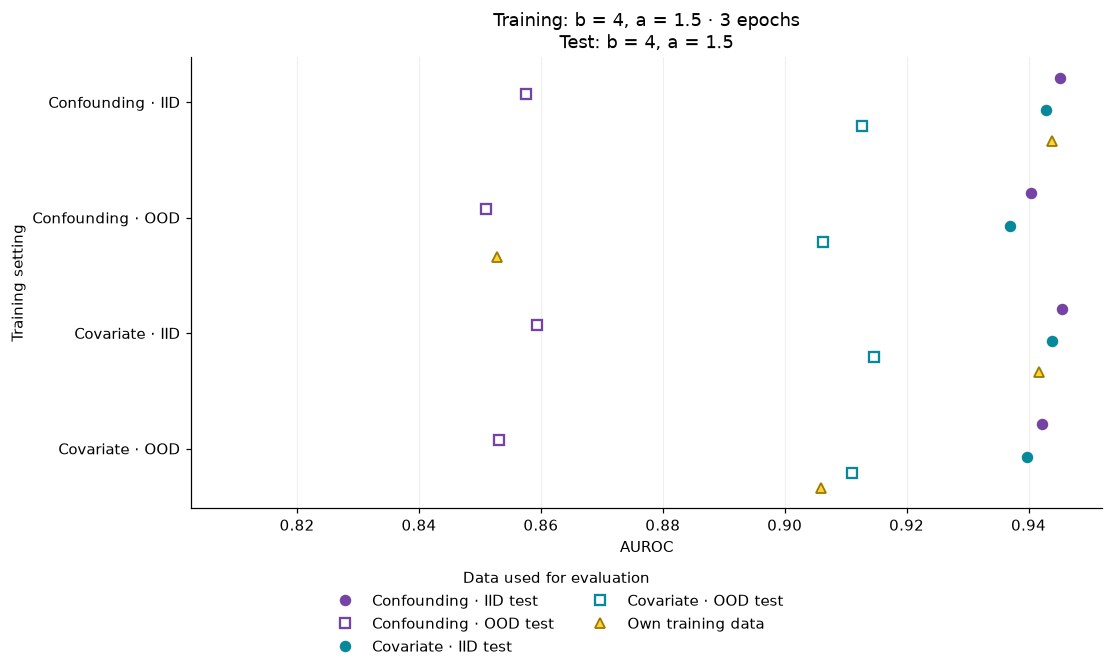

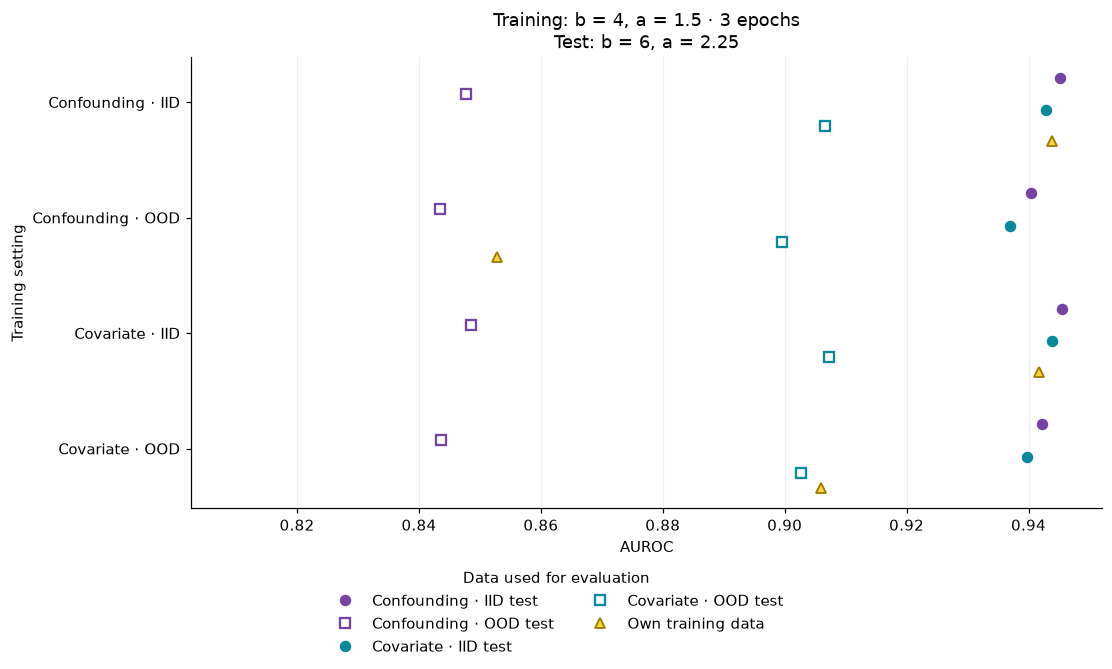

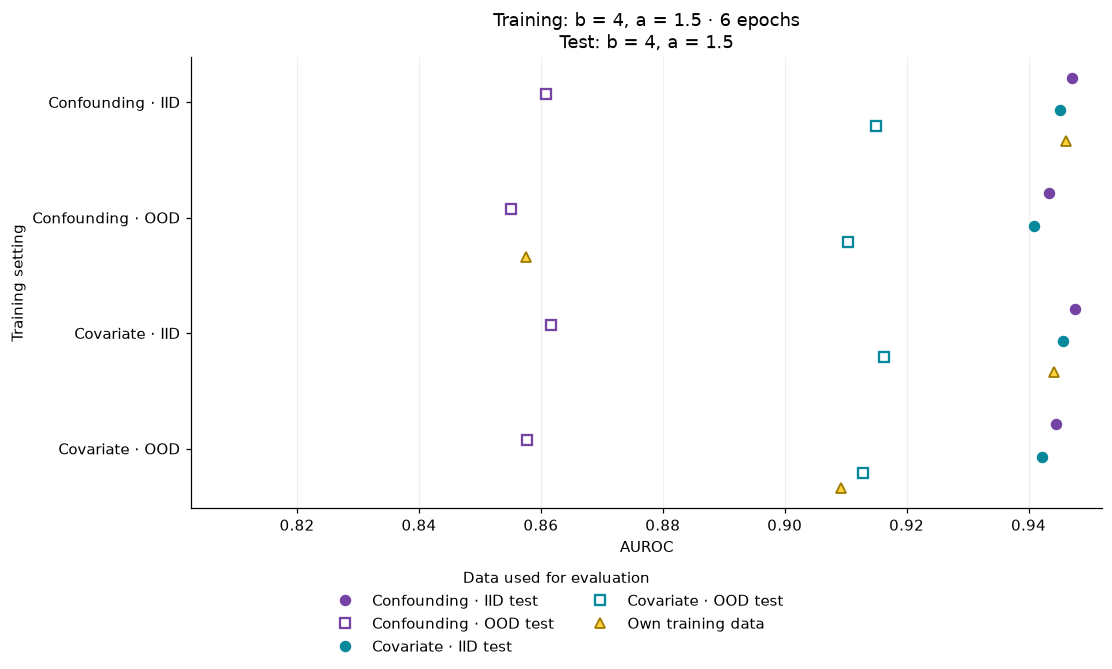

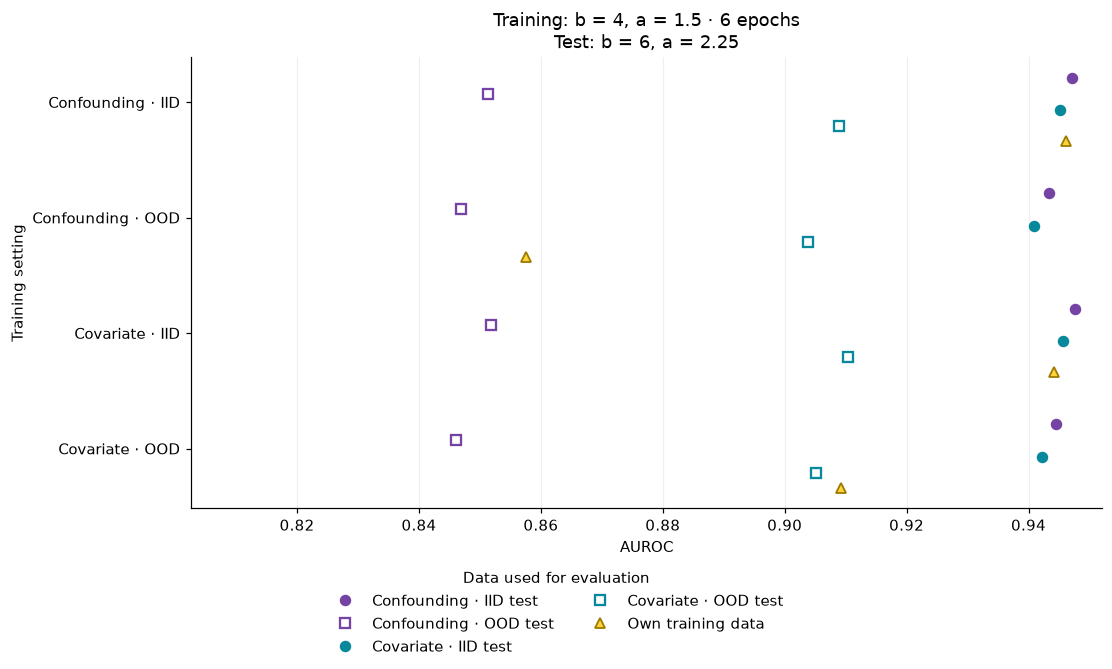

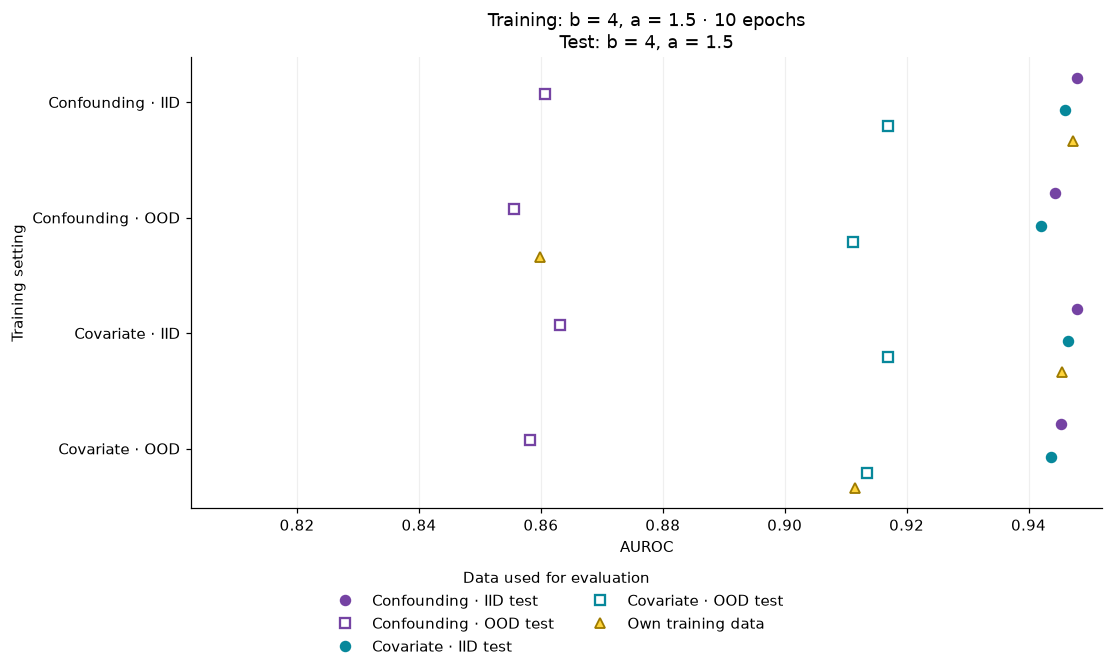

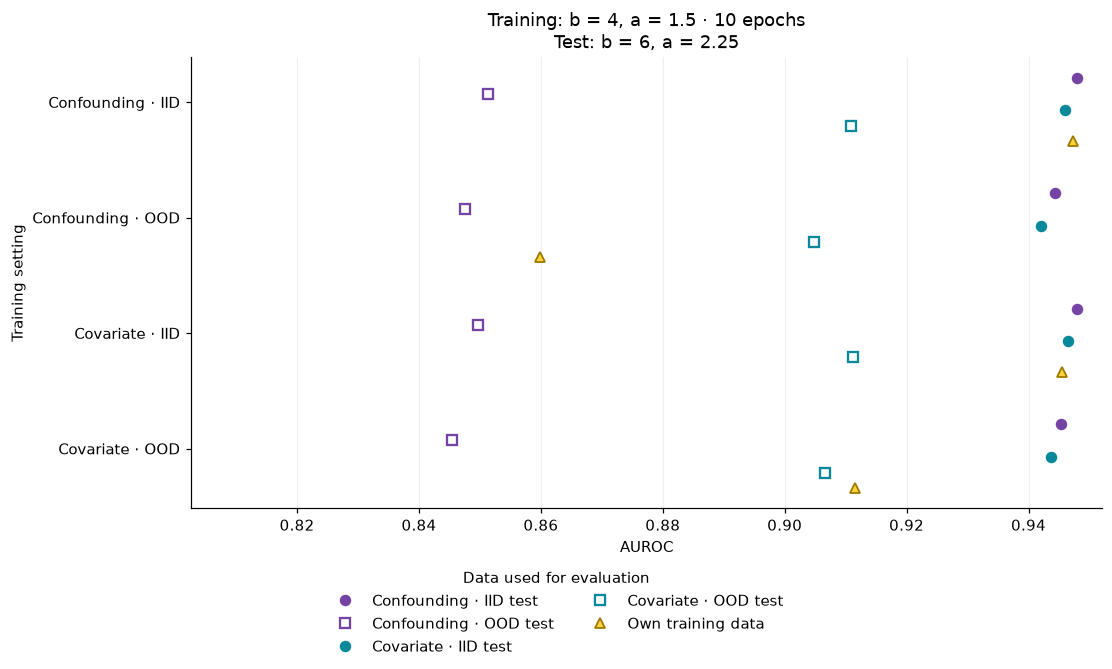

In [29]:
for epoch in epoch_budgets:
    plot_epoch_auroc(4, 1.5, epoch)
    plot_epoch_auroc(4, 1.5, epoch, stronger_test=True)

### Fixed b = 20, a = 2: 3, 6 and 10 epochs

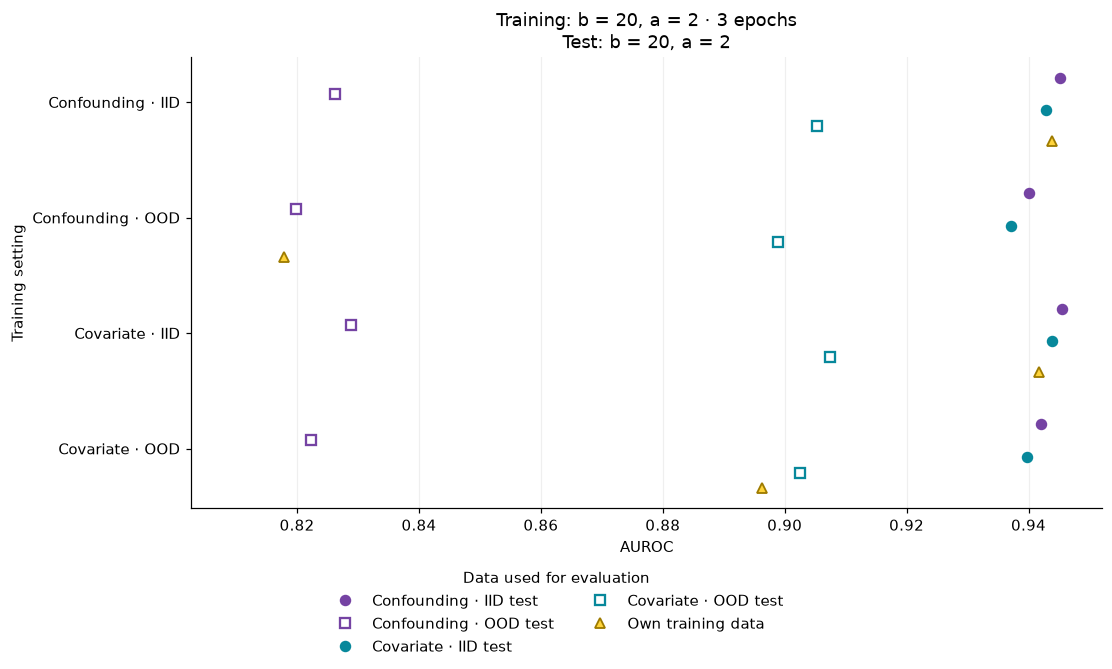

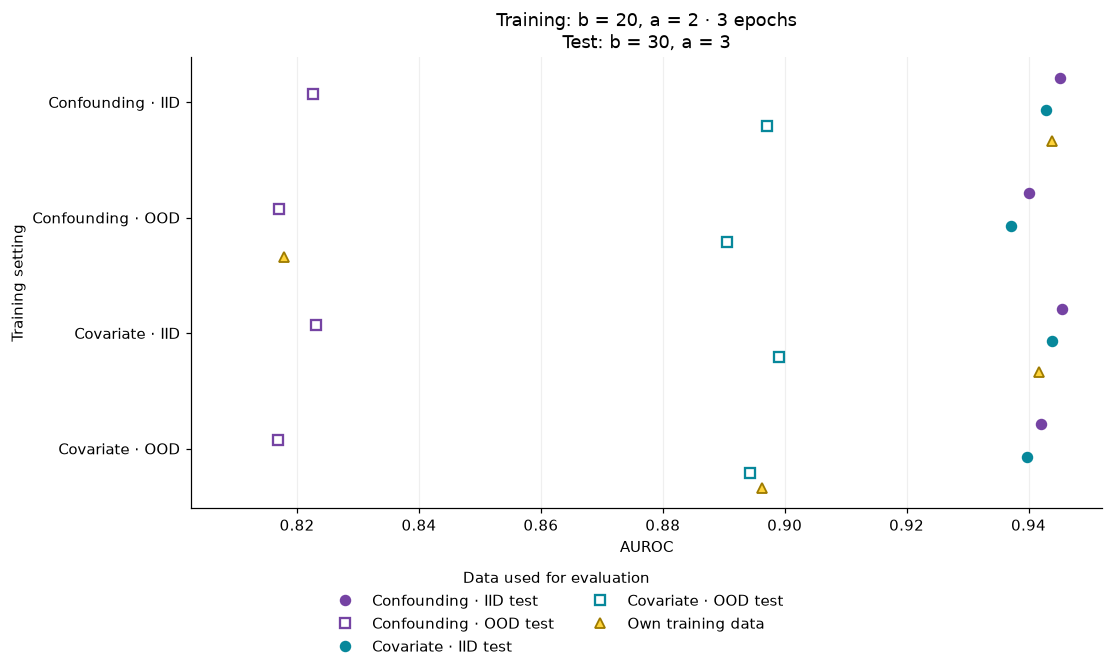

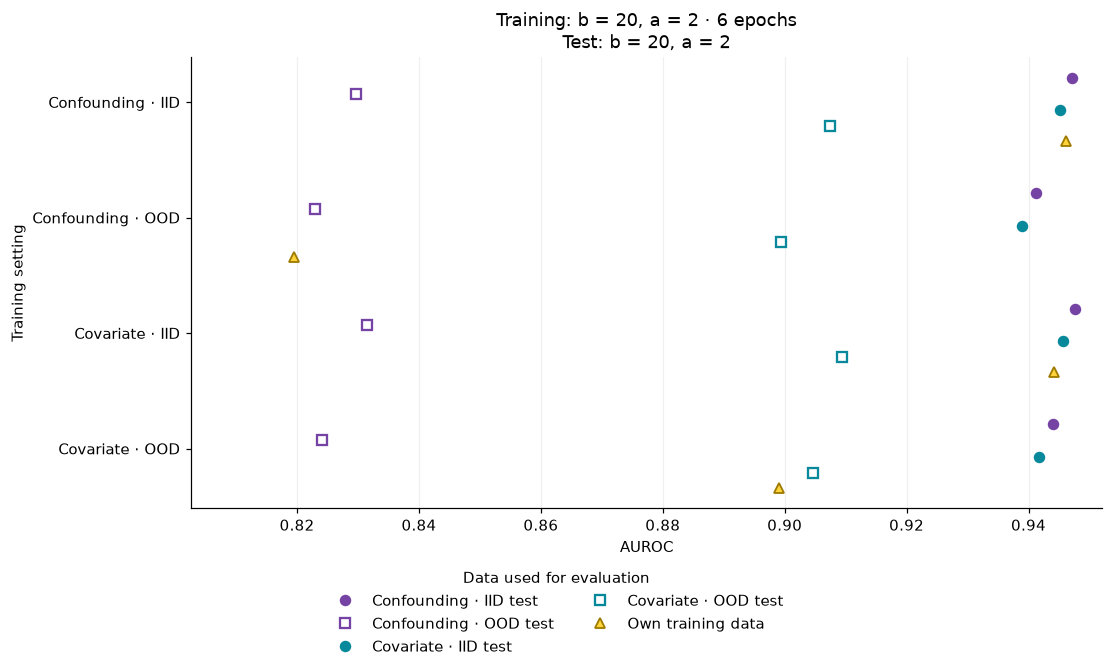

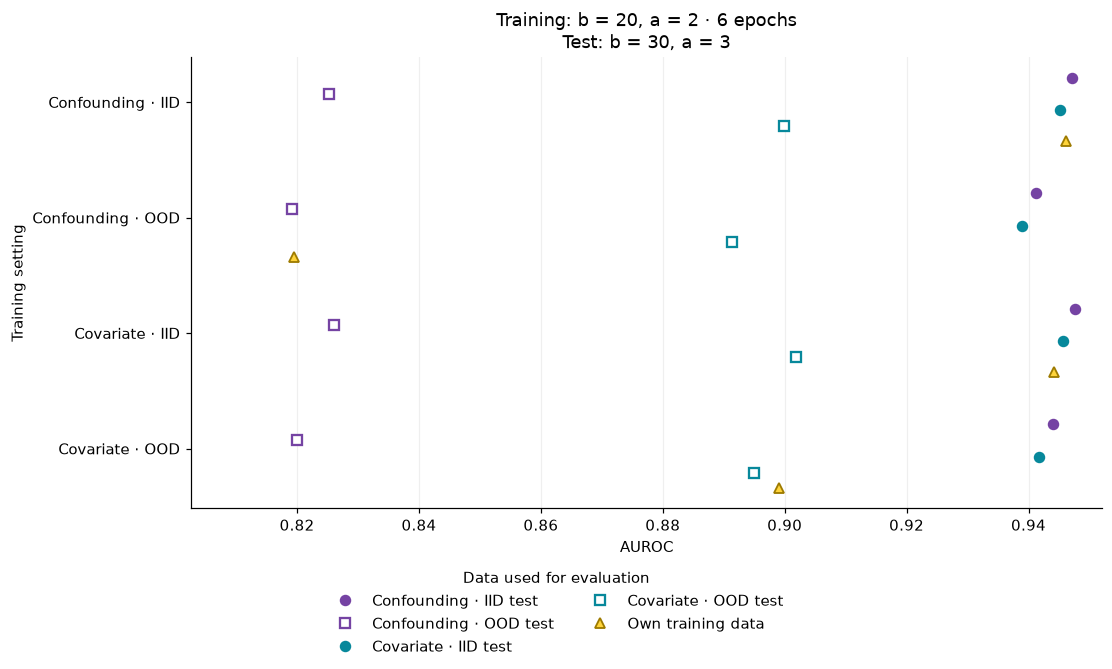

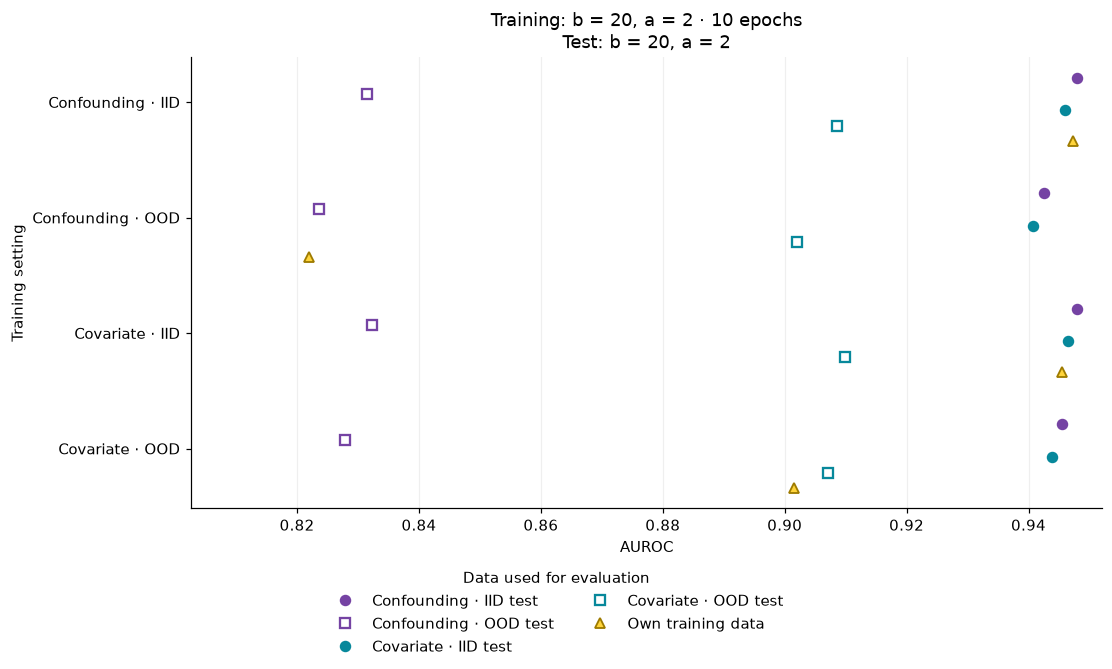

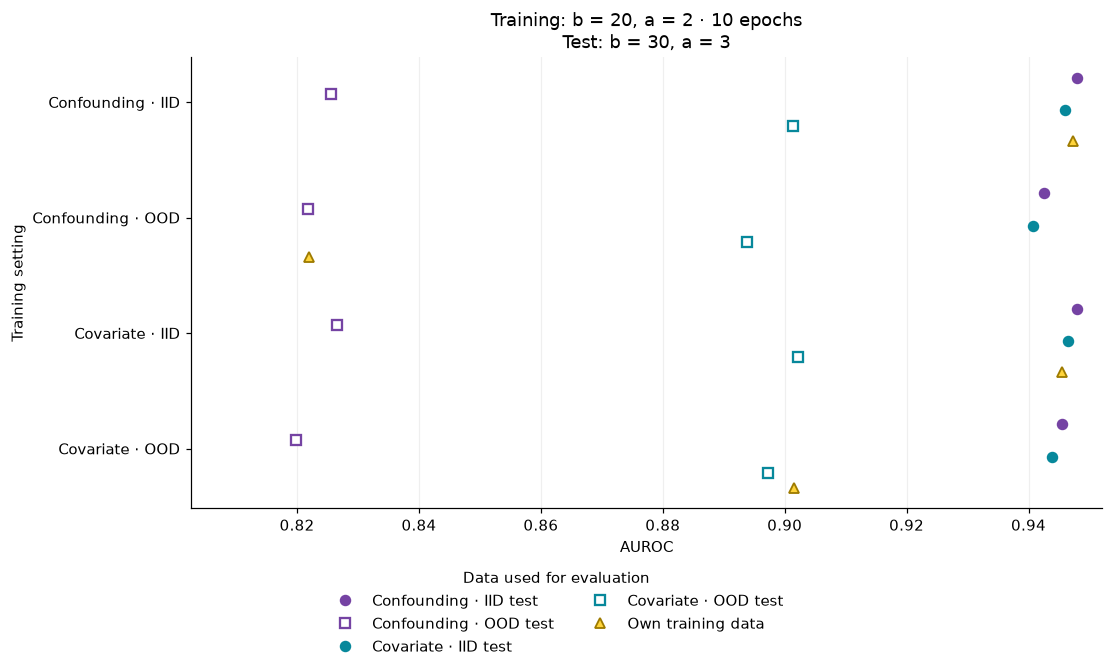

In [30]:
for epoch in epoch_budgets:
    plot_epoch_auroc(20, 2, epoch)
    plot_epoch_auroc(20, 2, epoch, stronger_test=True)

### Fixed b = 60, a = 3: 3, 6 and 10 epochs

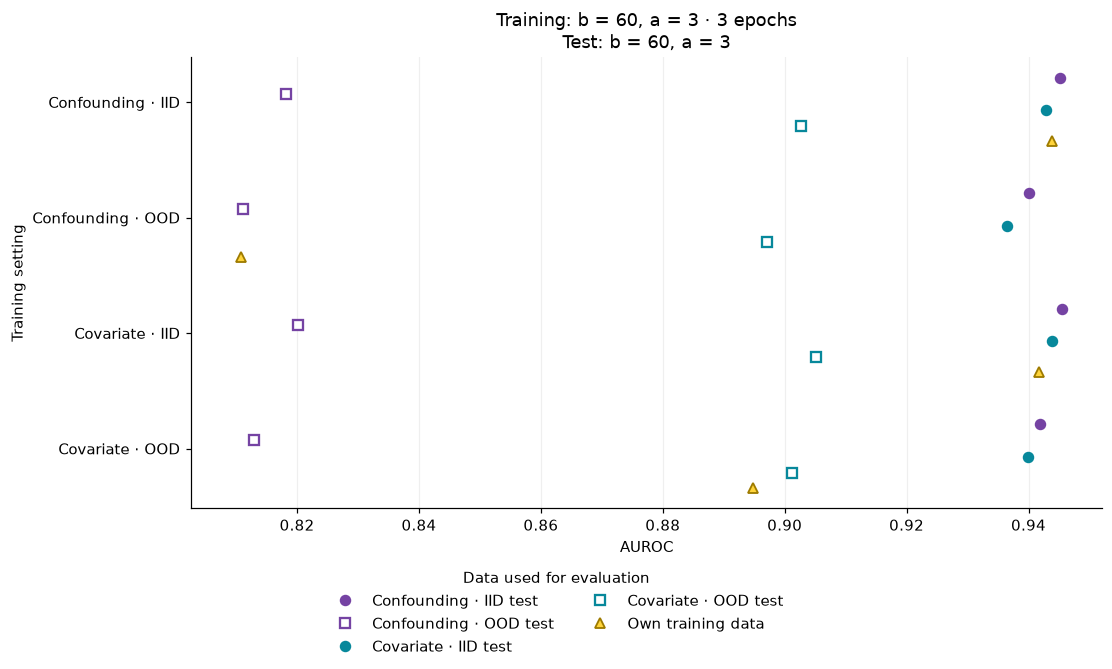

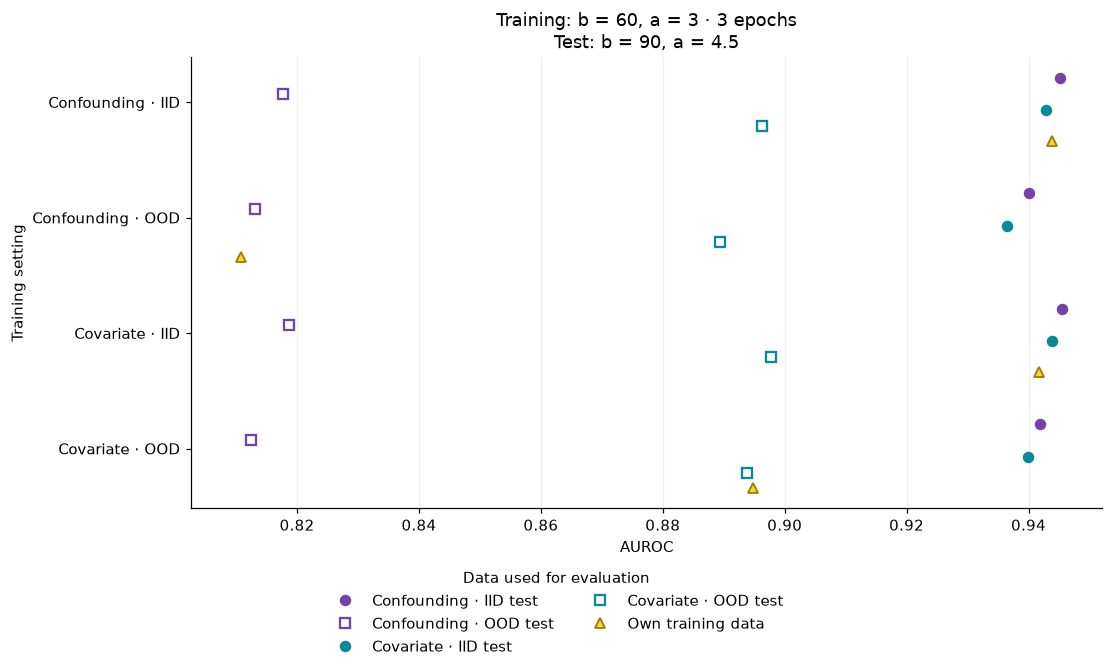

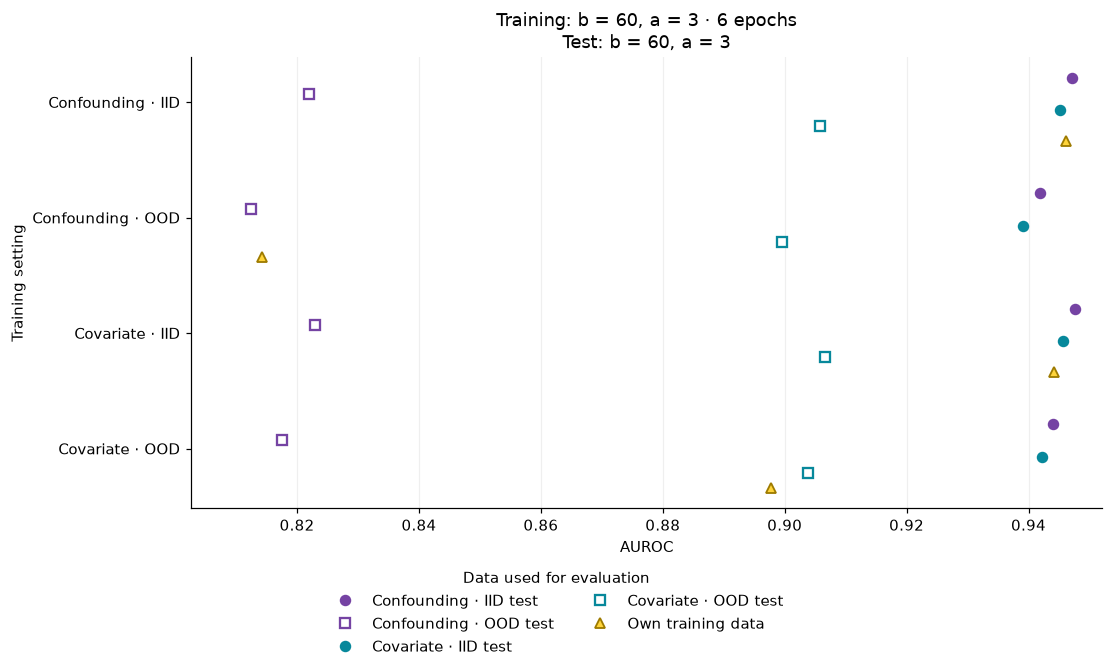

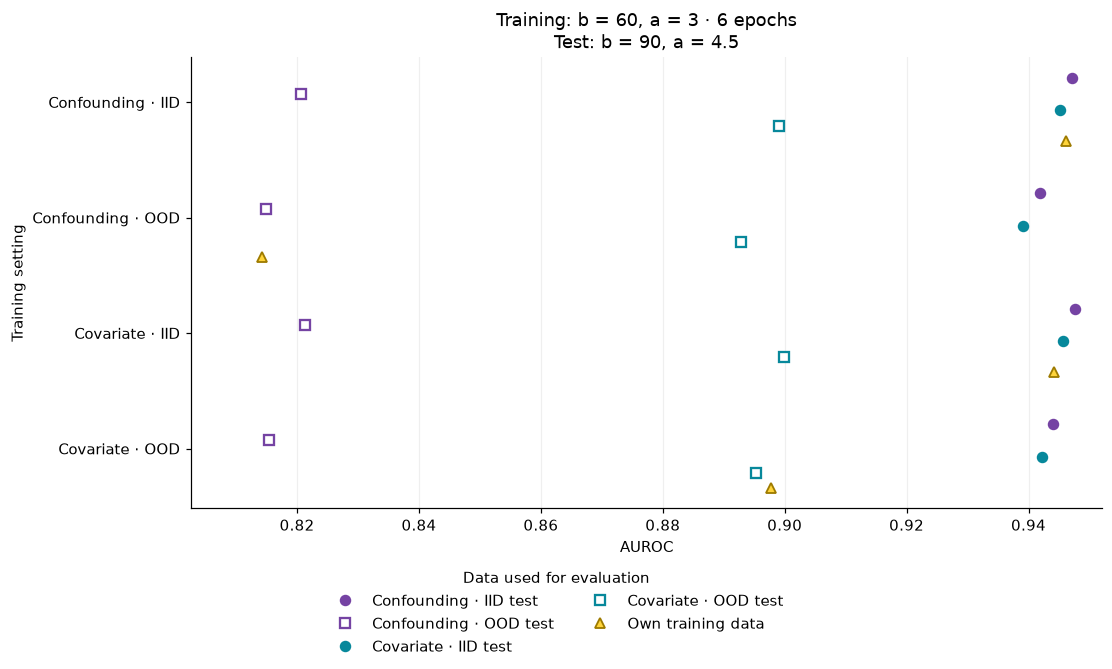

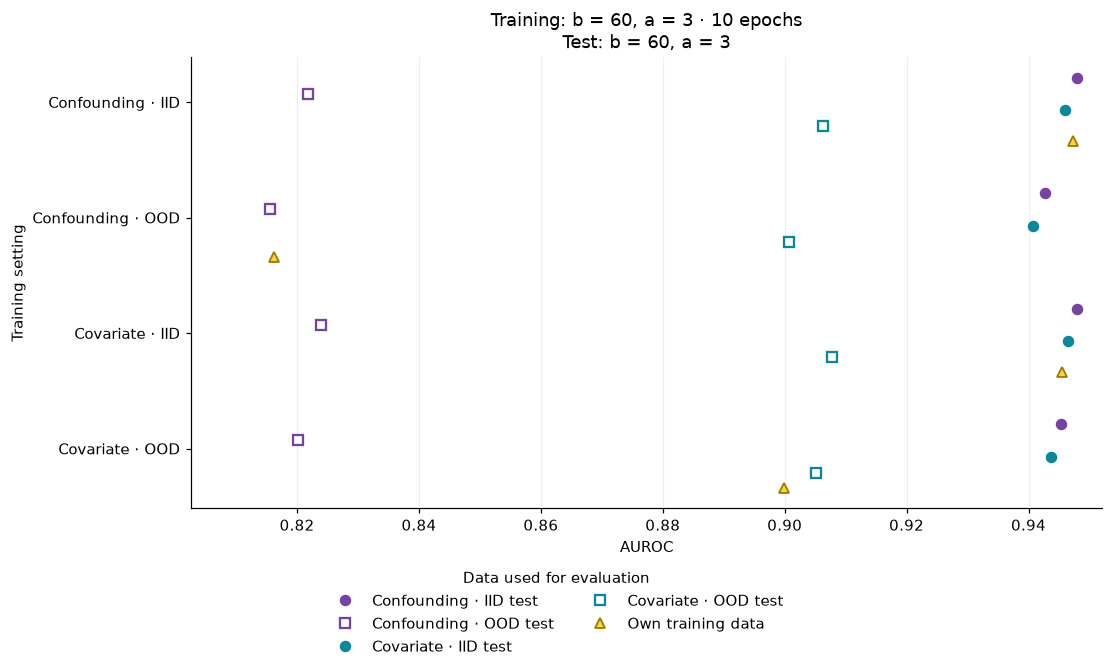

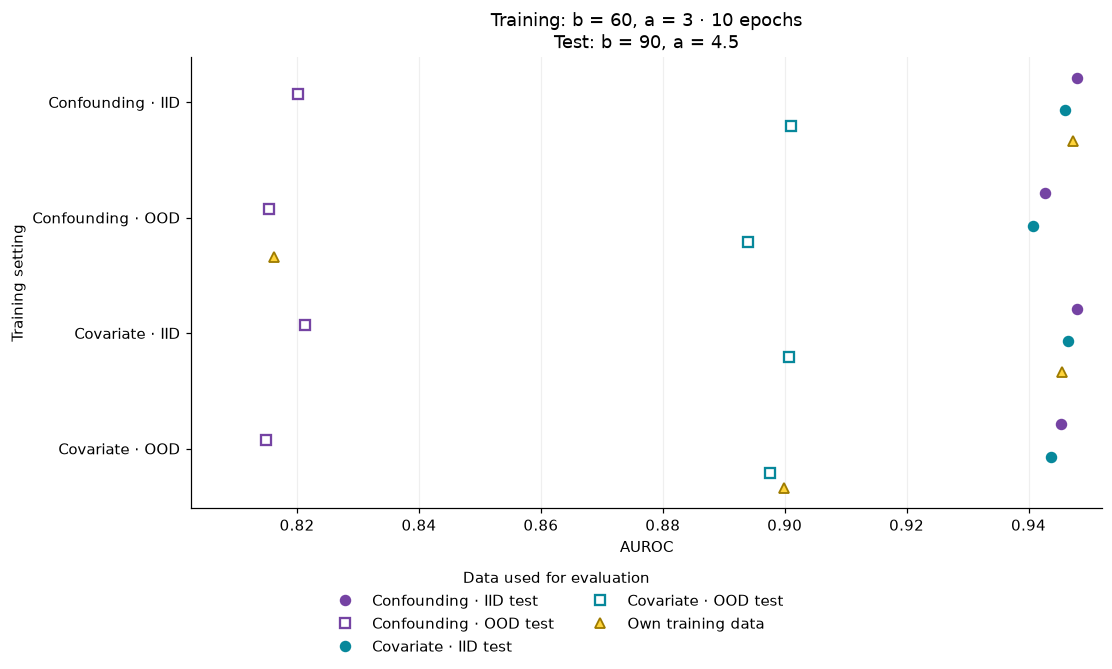

In [31]:
for epoch in epoch_budgets:
    plot_epoch_auroc(60, 3, epoch)
    plot_epoch_auroc(60, 3, epoch, stronger_test=True)

### Fixed b = 100, a = 4: 3, 6 and 10 epochs

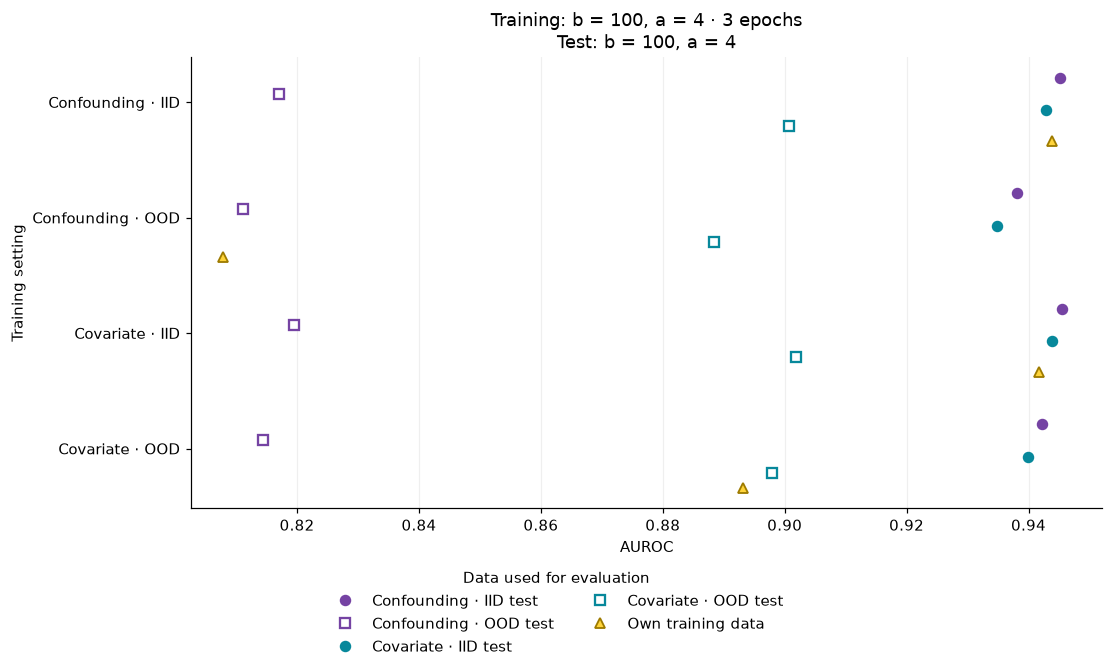

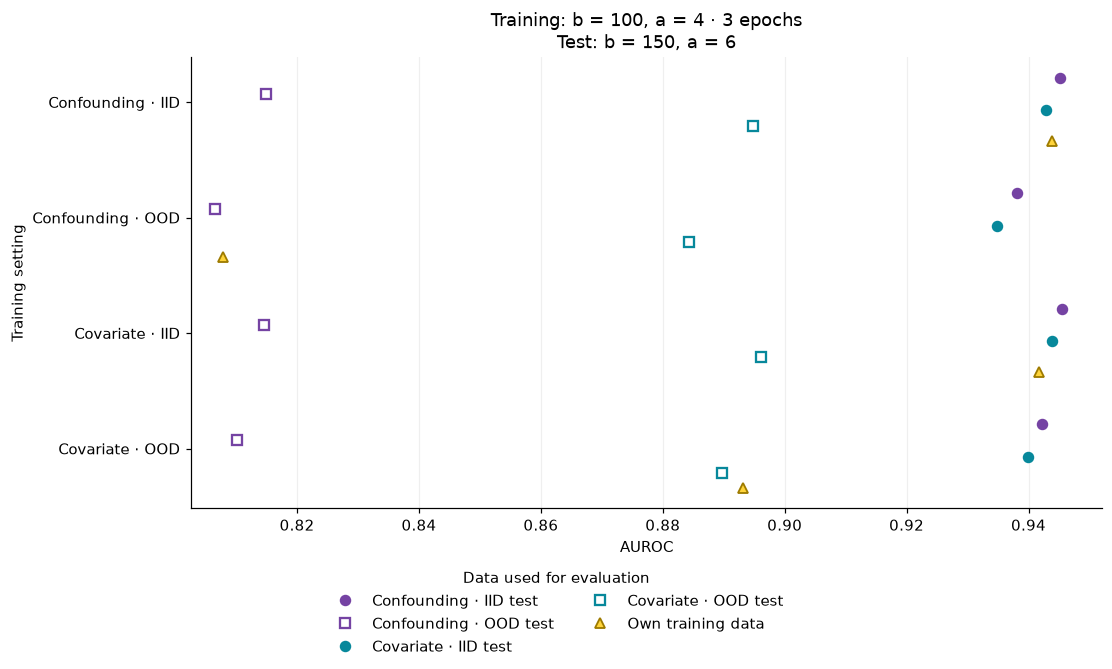

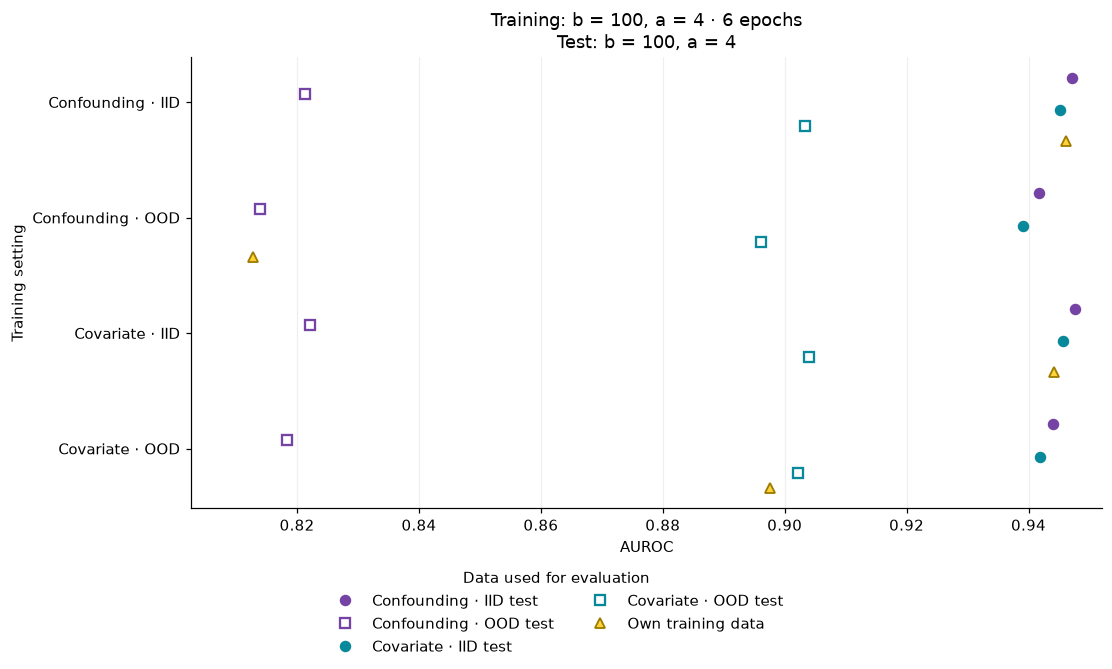

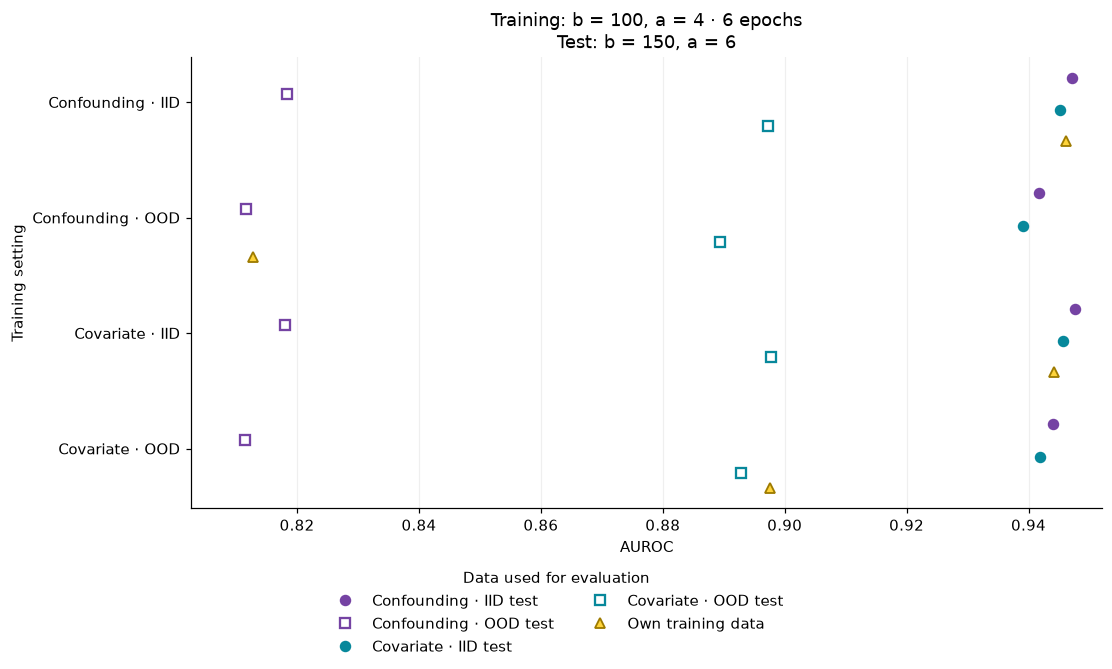

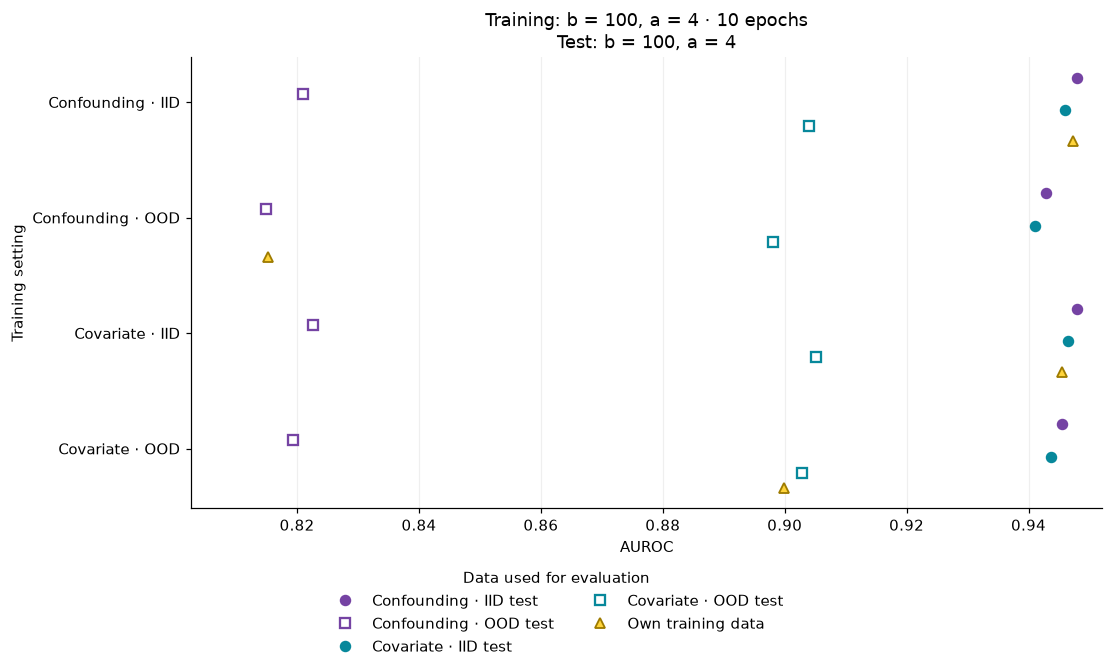

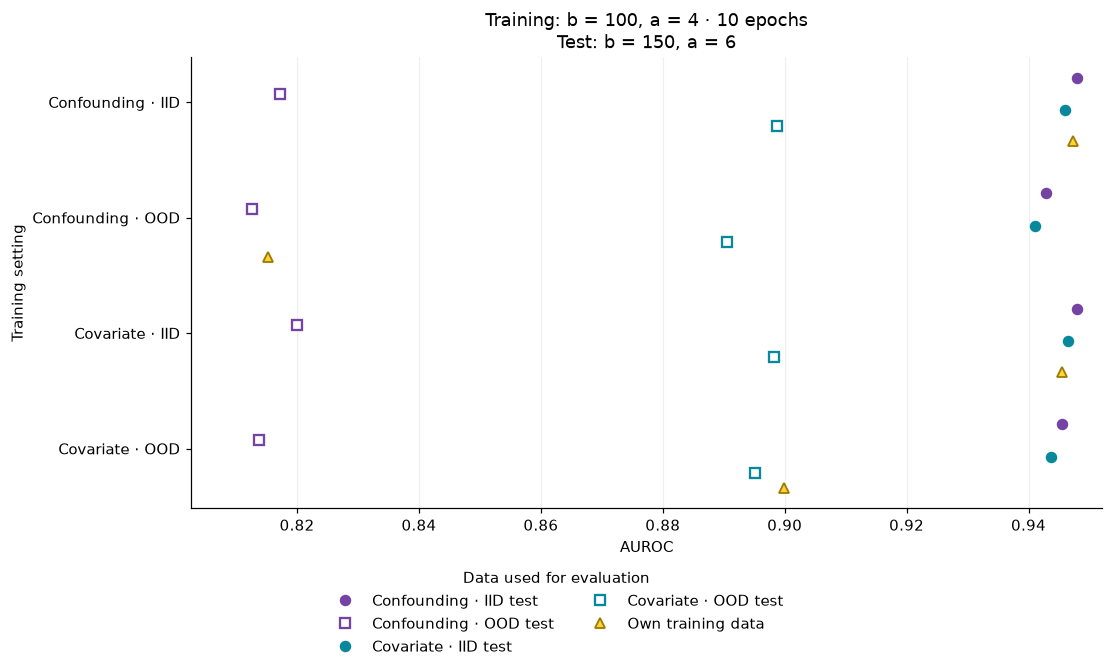

In [32]:
for epoch in epoch_budgets:
    plot_epoch_auroc(100, 4, epoch)
    plot_epoch_auroc(100, 4, epoch, stronger_test=True)

## 9. Larger tables and training banks: fixed b = 2, a = 1.5

This experiment keeps the **Nano architecture (356,066 parameters)**, **batch size 32**,
the Graph-U generators and seeded whole-batch shuffling. Each task is one synthetic
table; the training bank is a collection of these tasks. The data sizes change as follows:

| Setting | Earlier small-table experiments | This experiment |
|---|---:|---:|
| Rows per task (support + query) | 150 | **1,000** |
| Observed features per task | 5 | **8** |
| Training tasks per model condition | 80,000 | **500,000** |
| Validation tasks per condition | 3,200 | **32,000** |
| Test tasks per condition | 3,200 | **32,000** |
| Repetitions | Five in the original runs; one in the previous epoch sweep | **One** |
| Epoch budgets in the multi-epoch sweep | 3, 6, 10 | **1, 3, 9** |

There are still four training settings: confounding/covariate and IID/OOD.
The hidden variable U remains unobserved. Every OOD training, validation and
test task uses **fixed b = 2 and a = 1.5**; IID uses b = 0 and a = 1.
The magnitudes are not sampled across tasks. These are the original default fixed
magnitudes, rather than the larger pairs in the preceding sections.

For each training setting and epoch budget, all three learning rates
(**0.0007, 0.001, 0.002**) train for the full budget. Matching-condition validation
AUROC selects one winner: **36 candidates and 12 selected models**. Each model
reuses its own 500,000 tasks across epochs, reshuffling the 15,625 whole batches
each epoch. The budgets therefore contain **15,625, 46,875 and 140,625 updates**.

Each winner is evaluated on all four 32,000-task test banks. A **yellow triangle**
shows its AUROC on its own 500,000-task training bank, scoring query rows with
fixed weights. Purple/teal denote confounding/covariate tests; filled circles are
IID tests and open squares are OOD tests. AUROC is averaged over tasks.
The three separate figures share axis limits, have no connecting lines and show
**no error bars**, since there is only one repetition.


In [33]:
LARGE_DIR = ROOT_DIR / "nano_large_r1000_f8_train500k"
large_summary, large_runs, large_training, large_train_runs, large_winners = [
    pd.read_csv(LARGE_DIR / f"{name}.csv")
    for name in ("summary", "per_repetition", "training_summary", "training_per_repetition", "winners")]
large_epochs = [1, 3, 9]
large_keys, large_model_keys = ["epochs"] + keys, ["epochs"] + keys[:2]
large_cases = {(epoch, *case) for epoch in large_epochs for case in expected}
large_models = {(epoch, mode, condition) for epoch in large_epochs
                for mode in modes for condition in conditions}
for frame in (large_summary, large_runs):
    assert len(frame) == 48 and not frame.duplicated(large_keys).any()
    assert set(frame.set_index(large_keys).index) == large_cases
    assert frame["rows"].eq(1000).all() and frame["features"].eq(8).all()
    assert frame["fixed_location"].eq(2).all() and frame["fixed_scale"].eq(1.5).all()
for frame in (large_training, large_train_runs, large_winners):
    assert len(frame) == 12 and not frame.duplicated(large_model_keys).any()
    assert set(frame.set_index(large_model_keys).index) == large_models
assert large_summary["train_tasks"].eq(500000).all() and large_summary["test_tasks"].eq(32000).all()
assert large_summary["repetition_count"].eq(1).all() and large_training["repetition_count"].eq(1).all()
assert large_runs["task_count"].eq(32000).all() and large_train_runs["task_count"].eq(500000).all()
assert large_training["task_count_per_repetition"].eq(500000).all()
assert large_winners["learning_rate"].isin([0.0007, 0.001, 0.002]).all()
assert large_winners["checkpoint_sha256"].nunique() == 12
for summary, raw, group_keys in ((large_summary, large_runs, large_keys),
                                 (large_training, large_train_runs, large_model_keys)):
    np.testing.assert_allclose(
        summary.set_index(group_keys).sort_index()[[f"{metric}_mean" for metric in metrics]],
        raw.set_index(group_keys).sort_index()[metrics], rtol=0, atol=1e-12)
    assert raw["repetition"].eq(1).all() and raw["model_seed"].eq(42).all()
    assert raw["training_steps"].eq(15625 * raw["epochs"]).all()
    assert raw["shuffle_batches"].eq(True).all()
    assert raw["batch_order_scheme"].eq("seedsequence_model_epoch_v1").all()
    binding = large_model_keys + ["checkpoint_sha256", "learning_rate"]
    assert len(raw.merge(large_winners[binding], on=binding, validate="many_to_one")) == len(raw)
for frame in (large_training, large_train_runs):
    assert frame["evaluation_split"].eq("training").all() and frame["scored_rows"].eq("query").all()
for frame in (large_runs, large_train_runs):
    for prefix in (["training", "test"] if frame is large_runs else ["training"]):
        for parameter, shifted, iid in (("location", 2, 0), ("scale", 1.5, 1)):
            np.testing.assert_allclose(frame[f"{prefix}_query_{parameter}"],
                np.where(frame[f"{prefix}_condition"].eq("identity"), iid, shifted))
for frame in (large_summary, large_training, large_winners):
    frame["model"] = frame[keys[0]].str.title() + " · " + frame[keys[1]].map(condition_labels)
large_summary["test"] = (large_summary[keys[2]].str.title() + " · "
                         + large_summary[keys[3]].map(condition_labels))
print("Loaded 12 selected models, 48 test comparisons and 12 own-training scores; "
      "table sizes, fixed shifts, epoch budgets and selected checkpoints verified.")


Loaded 12 selected models, 48 test comparisons and 12 own-training scores; table sizes, fixed shifts, epoch budgets and selected checkpoints verified.


In [34]:
large_selection = large_winners.set_index(["epochs", "model"])[["learning_rate", "validation_roc_auc"]]
large_selection = large_selection.reindex(pd.MultiIndex.from_product(
    [large_epochs, order], names=["epochs", "model"]))
display(large_selection.rename_axis(index=["Epochs", "Training setting"])
        .rename(columns={"learning_rate": "Selected LR", "validation_roc_auc": "Validation AUROC"})
        .style.format({"Selected LR": "{:.4f}", "Validation AUROC": "{:.4f}"})
        .set_caption("Learning rates selected using matching-condition validation AUROC"))


In [35]:
large_auc_values = pd.concat([large_summary["roc_auc_mean"], large_training["roc_auc_mean"]])
large_xlim = (large_auc_values.min() - 0.004, large_auc_values.max() + 0.004)

def plot_large_auroc(epochs):
    subset = large_summary.loc[large_summary["epochs"].eq(epochs)]
    means = subset.pivot(index="model", columns="test", values="roc_auc_mean").reindex(
        index=order, columns=order)
    train = large_training.loc[large_training["epochs"].eq(epochs)].set_index("model").reindex(order)
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    for j, offset in enumerate(np.linspace(-0.21, 0.21, 4)):
        iid, color = j % 2 == 0, colors[j // 2]
        ax.plot(means.iloc[:, j], np.arange(4) + offset, linestyle="none",
                marker="o" if iid else "s", markersize=6, markeredgewidth=1.5,
                color=color, markerfacecolor=color if iid else "white",
                label=f"{modes[j // 2].title()} · {'IID' if iid else 'OOD'} test")
    ax.plot(train["roc_auc_mean"], np.arange(4) + 0.34, linestyle="none", marker="^",
            markersize=7, markeredgewidth=1.2, color="#D4AA00",
            markerfacecolor="#FFD43B", markeredgecolor="#9E7B00", label="Own training data")
    ax.set_yticks(range(4), order)
    ax.invert_yaxis()
    ax.set(xlim=large_xlim, xlabel="AUROC", ylabel="Training setting",
           title="1,000 rows · 8 features · 500,000 training tasks\n"
                 f"Fixed train/test parameters: b = 2, a = 1.5 · {epochs} {'epoch' if epochs == 1 else 'epochs'}")
    ax.grid(axis="x", alpha=0.2)
    fig.legend(*ax.get_legend_handles_labels(), loc="outside lower center",
               ncol=2, frameon=False, title="Data used for evaluation")
    show_plot(fig, f"auroc_epochs_{epochs}", LARGE_DIR / "figures")


### 1 epoch

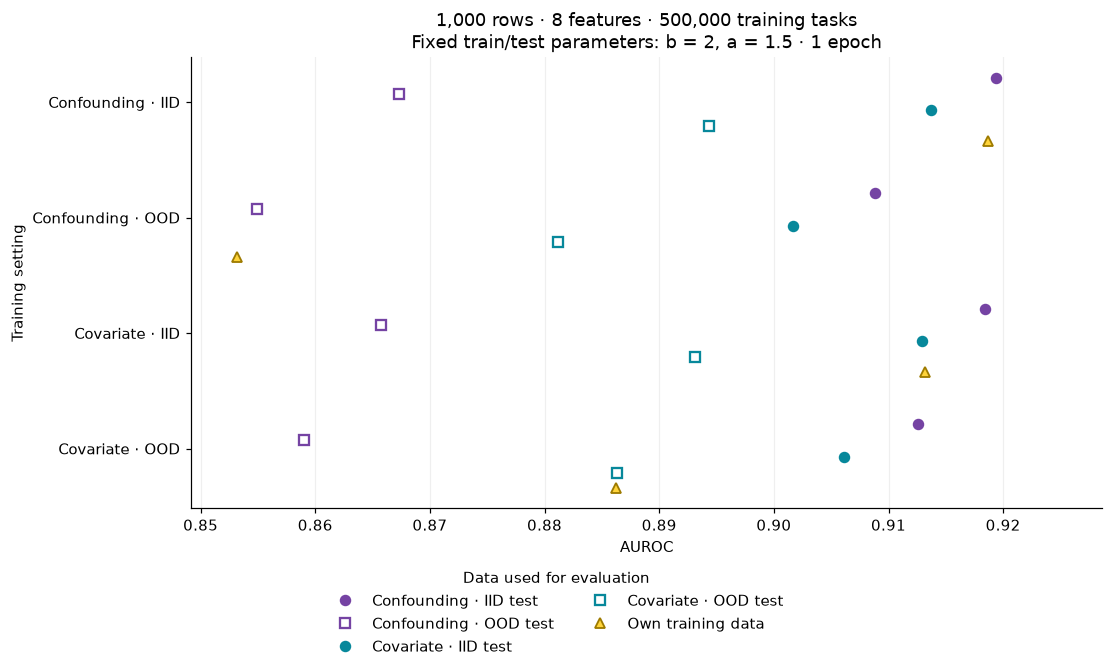

In [36]:
plot_large_auroc(1)

### 3 epochs

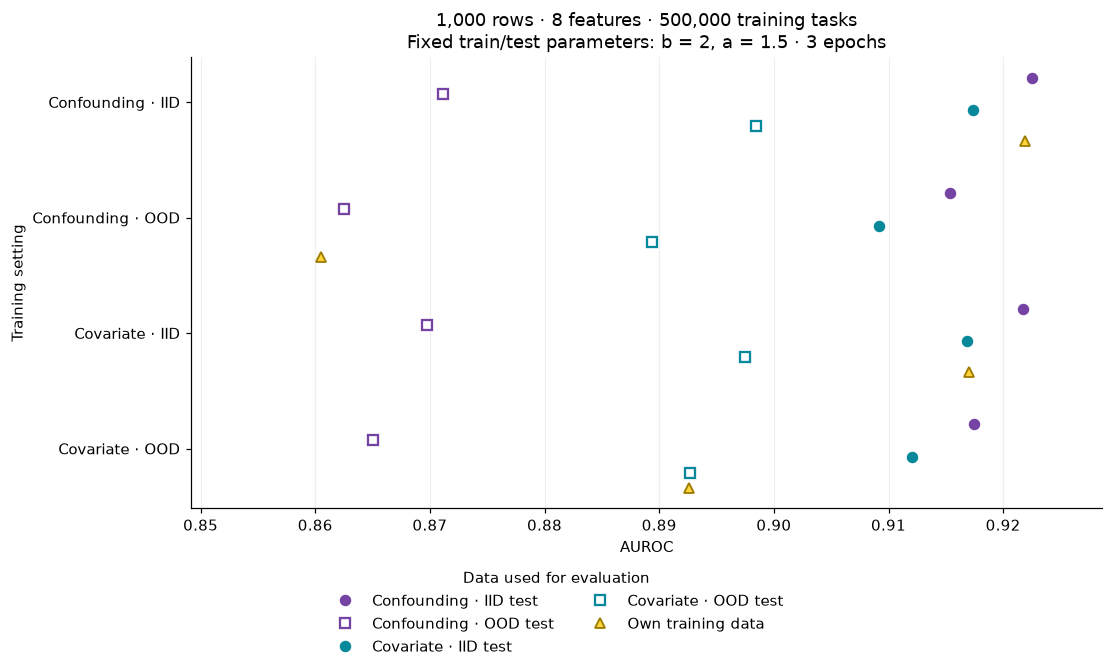

In [37]:
plot_large_auroc(3)

### 9 epochs

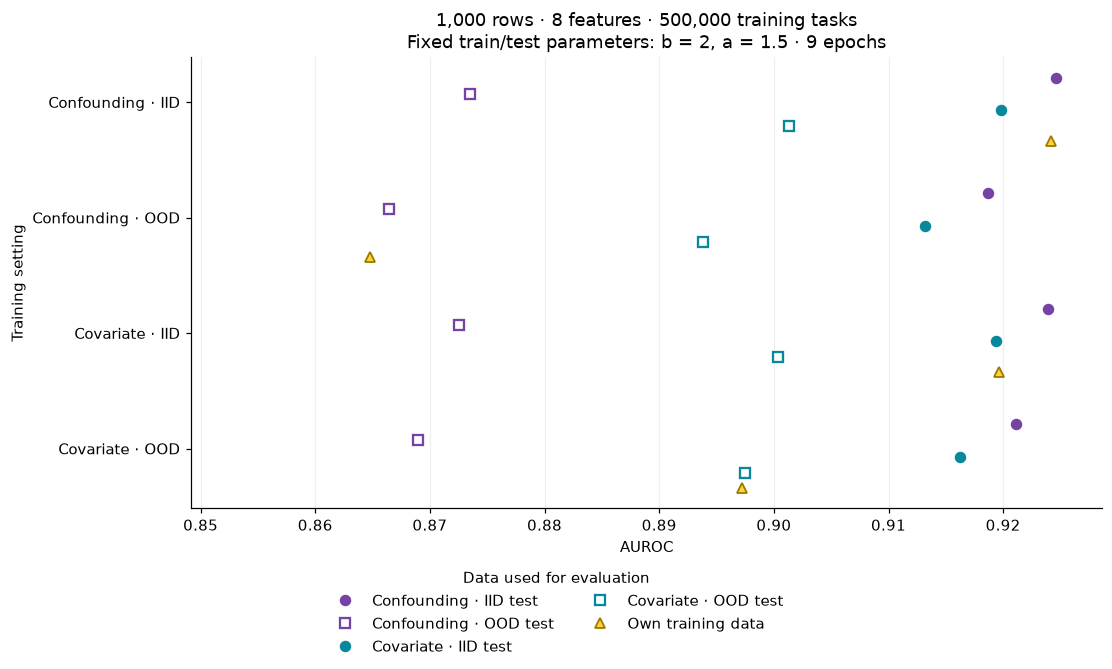

In [38]:
plot_large_auroc(9)